# Dataset 1 | Zhang 2018 — T-cell Atlas (GSE108989)

**Reference:** Zhang L. et al. (2018). *Lineage Tracking Reveals Dynamic Relationships of T Cells in Colorectal Cancer.* Nature, 564, 268–272. [DOI: 10.1038/s41586-018-0694-x](https://doi.org/10.1038/s41586-018-0694-x)

**Overview:** Exploration of T-cell diversity, tissue distribution and MSI-associated patterns in colorectal cancer (CRC).

| Dataset characteristics | Details |
|---|---|
| Patients | 12 (4 MSI-H, 8 MSS) |
| Sequenced cells | 11,138 |
| Main analysis | 8,530 CD4+/CD8+ T cells; 20 subclusters |
| Tissues | Tumor, adjacent normal tissue, peripheral blood |

**Workflow:** Metadata → cell composition → gene expression → PCA + t-SNE → MSI-H/MSS statistics → future machine learning.

**Statistical analysis:** Patient-level tumor T-cell percentages are compared using two-sided Mann–Whitney U and Welch t-tests, with Benjamini–Hochberg (BH-FDR) correction.

**Limitations:** FACS-based cell selection may affect observed proportions. The small patient cohort limits statistical power. t-SNE is used for exploratory visualization, not statistical inference.

**Scope:** All 12 patients are considered; comparisons with Zhang 2020 are performed separately.

## 1. Setup
Import libraries and define the original project folders.

In [46]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
from IPython.display import display

PROJECT_DIR = Path("/cfs/earth/scratch/suereser/crc_singlecell")
DATA_DIR = PROJECT_DIR / "data"

GSE108989_DIR = DATA_DIR / "2018_GSE108989"
RESULTS_DIR = PROJECT_DIR / "results" / "GSE108989"
RESULTS_DIR.mkdir(parents=True, exist_ok=True)


GSE146771_DIR = DATA_DIR / "2020_GSE146771"



In [47]:
def save_table(df, filename):
    output_path = RESULTS_DIR / filename
    df.to_csv(output_path, index=True)
    print(f"Saved: {output_path}")

def list_files(folder):
    """
    List all files in a folder together with their size in MB.
    """
    for file in sorted(folder.iterdir()):
        if file.is_file():
            size_mb = file.stat().st_size / (1024 ** 2)
            print(f"{file.name} | {size_mb:.2f} MB")

def inspect_matrix_preview(path, sep="\t", nrows=3, index_col=None, n_display_cols=6):
    """Read a few gene rows while retaining the full cell-column header."""
    preview = pd.read_csv(path, sep=sep, nrows=nrows,
                          compression="infer", index_col=index_col)
    print(f"File: {path.name}")
    print(f"Preview: {preview.shape[0]} gene rows × {preview.shape[1]} columns")
    print("First column names:", preview.columns[:n_display_cols].tolist())
    display(preview.iloc[:, :n_display_cols])
    return preview


def count_and_percent(series, label):
    """Summarize category counts and percentages (excluding missing labels)."""
    counts = series.value_counts().rename_axis(label).reset_index(name="Cell_Count")
    counts["Percentage"] = (100 * counts["Cell_Count"] /
                            counts["Cell_Count"].sum()).round(2)
    return counts


def show_bar_table(table, category_col, title, figsize=(10, 6)):
    """Display a count table and its matching horizontal bar chart."""
    display(table)
    ax = table.plot.barh(x=category_col, y="Cell_Count", legend=False,
                         figsize=figsize)
    ax.invert_yaxis()
    ax.set(title=title, xlabel="Number of cells", ylabel=category_col)
    plt.tight_layout()
    plt.show()


def show_compact_distribution(table, category_col, title, figsize=(8, 4), color="#4C78A8"):
    """Display a compact horizontal bar chart with count and percent labels."""
    display(table)
    fig, ax = plt.subplots(figsize=figsize)
    bars = ax.barh(table[category_col], table["Cell_Count"], color=color)
    ax.invert_yaxis()
    ax.set(title=title, xlabel="Number of cells", ylabel="")
    max_count = max(table["Cell_Count"].max(), 1)
    for bar, count, pct in zip(bars, table["Cell_Count"], table["Percentage"]):
        ax.text(bar.get_width() + max_count * 0.01,
                bar.get_y() + bar.get_height()/2,
                f"{count} ({pct:.1f}%)",
                va="center", fontsize=9)
    # Leave enough space for value labels
    ax.set_xlim(0, max_count * 1.30)    
    plt.tight_layout()
    plt.show()


## 2. Data and metadata
Load the published metadata and check the patient, tissue and cluster annotations.

### 2.1 Available files

In [48]:
list_files(GSE108989_DIR)

GSE108989_CRC.TCell.S10805.norm.centered.txt.gz | 368.54 MB
GSE108989_CRC.TCell.S11138.TPM.txt.gz | 351.58 MB
GSE108989_CRC.TCell.S11138.count.txt.gz | 69.67 MB
GSE108989_CRC.bulk.S12.TPM.tab.gz | 2.12 MB
GSE108989_CRC.bulk.S12.count.tab.gz | 0.56 MB
GSE108989_CRC.bulk.exome.mutation.tab.gz | 0.13 MB
GSE108989_cell_metadata_full.htm | 0.42 MB


### 2.2 Load metadata and assign MSI status
Use the **12 patient labels reported in Zhang et al. (2018)**, without filtering for overlap with Zhang 2020.

Metadata shape: (11138, 4)
Columns: ['UniqueCell_ID', 'Patient_ID', 'majorCluster', 'sampleType']


,UniqueCell_ID,Patient_ID,majorCluster,sampleType
0,NTH5-20180123,P0123,CD4_C01-CCR7,NTH
1,NTH64-20180123,P0123,CD4_C01-CCR7,NTH
2,NTR57-20180123,P0123,CD4_C01-CCR7,NTR
3,PP7-100-20180123,P0123,CD4_C01-CCR7,PP7
4,PP7-106-20180123,P0123,CD4_C01-CCR7,PP7


Patients by MSI status:


,Patient_ID,MSI_Status
0,P0123,MSI-H
70,P0215,MSS
114,P0309,MSS
155,P0411,MSS
194,P0413,MSI-H
238,P0701,MSS
282,P0825,MSI-H
311,P0909,MSI-H
366,P1012,MSS
5016,P1207,MSS


,MSI_Status,Cell_Count,Percentage
0,MSS,8,66.67
1,MSI-H,4,33.33


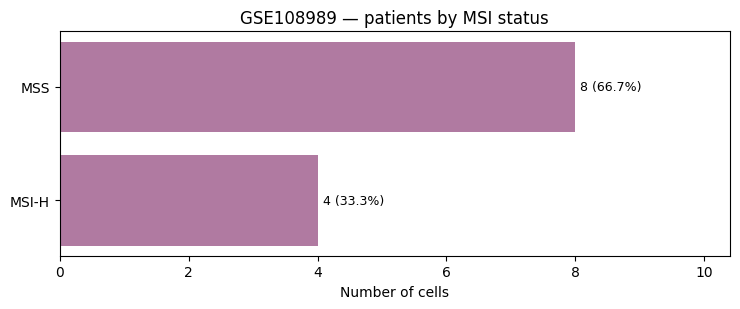

Cells by tissue:


,Tissue,Cell_Count,Percentage
0,Tumor,5149,46.23
1,Peripheral Blood,3352,30.10
2,Normal,2637,23.68


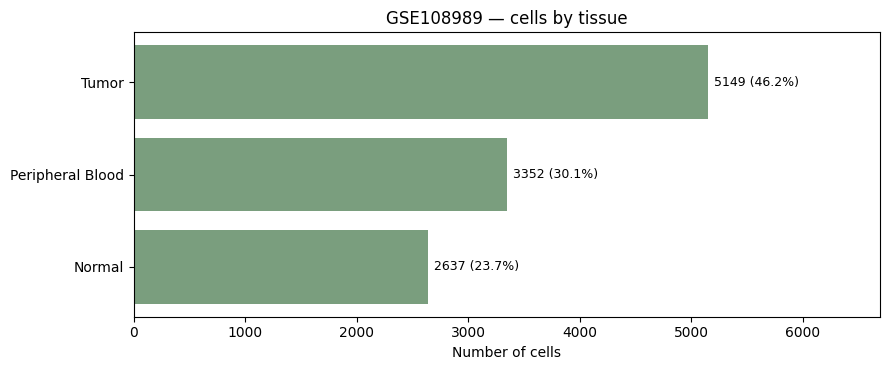

In [49]:

from bs4 import BeautifulSoup
from io import StringIO

html_path = GSE108989_DIR / "GSE108989_cell_metadata_full.htm"
with open(html_path, encoding="utf-8") as f:
    soup = BeautifulSoup(f, "html.parser")
pre = soup.find("pre")
if pre is None:
    raise ValueError("No <pre> block found in the GSE108989 metadata HTML.")

gse108989_metadata = pd.read_csv(StringIO(pre.get_text()), sep="	", comment="#")
gse108989_metadata.columns = gse108989_metadata.columns.str.strip()

print("Metadata shape:", gse108989_metadata.shape)
print("Columns:", gse108989_metadata.columns.tolist())
display(gse108989_metadata.head())

MSI_H_PATIENTS = {"P0413", "P0825", "P0123", "P0909"}
MSS_PATIENTS = {"P0215", "P0411", "P0701", "P1012", "P1207", "P1212", "P1228", "P0309"}
MSI_MAP = {**{p: "MSI-H" for p in MSI_H_PATIENTS}, **{p: "MSS" for p in MSS_PATIENTS}}
gse108989_metadata["Patient_ID"] = gse108989_metadata["Patient_ID"].astype(str).str.strip()
gse108989_metadata["MSI_Status"] = gse108989_metadata["Patient_ID"].map(MSI_MAP)
gse108989_metadata["Tissue"] = gse108989_metadata["sampleType"].astype(str).str[0].map(
    {"N": "Normal", "P": "Peripheral Blood", "T": "Tumor"}
)
gse108989_metadata["T_Cell_Type"] = gse108989_metadata["majorCluster"].astype(str).str[:3].map(
    {"CD4": "CD4+", "CD8": "CD8+"}
)
assert gse108989_metadata["MSI_Status"].notna().all(), "Unmapped patient IDs: " + str(gse108989_metadata.loc[gse108989_metadata["MSI_Status"].isna(), "Patient_ID"].unique())
assert set(gse108989_metadata["Patient_ID"]) == set(MSI_MAP), "Check the 12 patient IDs against the paper."

print("Patients by MSI status:")
patient_status_table = gse108989_metadata[["Patient_ID", "MSI_Status"]].drop_duplicates().sort_values("Patient_ID")
display(patient_status_table)
patient_status_summary = count_and_percent(patient_status_table["MSI_Status"], "MSI_Status")
show_compact_distribution(
    patient_status_summary,
    "MSI_Status",
    "GSE108989 — patients by MSI status",
    figsize=(7.5, 3.2),
    color="#B07AA1"
)

print("Cells by tissue:")
tissue_table = count_and_percent(gse108989_metadata["Tissue"], "Tissue")
show_compact_distribution(
    tissue_table,
    "Tissue",
    "GSE108989 — cells by tissue",
    figsize=(9, 3.8),
    color="#7A9E7E"
)


### 2.3 Export clean metadata
Save the corrected MSI labels for later notebooks.

In [50]:
gse108989_metadata.to_csv(RESULTS_DIR / "cell_metadata.csv", index=False)
print("Saved corrected metadata:", RESULTS_DIR / "cell_metadata.csv")

Saved corrected metadata: /cfs/earth/scratch/suereser/crc_singlecell/results/GSE108989/cell_metadata.csv


## 3. Descriptive cell distributions
Start with a small overview of tissue proportions, then summarize patients, major T-cell groups, subclusters and sorting categories. Counts and percentages describe the **sequenced, FACS-sorted T cells**, not the unbiased cellular composition of whole tissues.

### 3.0 Overall tissue overview
A small first figure shows how many sequenced cells come from Tumor, Peripheral Blood and Normal samples.

,Tissue,Cell_Count,Percentage
0,Tumor,5149,46.23
1,Peripheral Blood,3352,30.10
2,Normal,2637,23.68


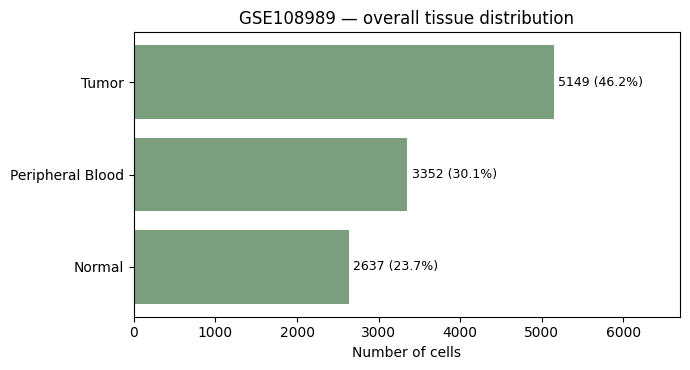

In [51]:

tissue_overview = count_and_percent(gse108989_metadata["Tissue"], "Tissue")
show_compact_distribution(
    tissue_overview,
    "Tissue",
    "GSE108989 — overall tissue distribution",
    figsize=(7, 3.8),
    color="#7A9E7E"
)


### 3.1 Cells per patient
First check whether the sequenced-cell counts are relatively balanced across the 12 patients.

,Patient_ID,Cell_Count,Percentage
0,P0825,1253,11.25
1,P0123,1238,11.12
2,P1228,1210,10.86
3,P1212,1164,10.45
4,P0909,1105,9.92
5,P1012,1065,9.56
6,P0701,852,7.65
7,P0413,765,6.87
8,P0411,764,6.86
9,P0309,758,6.81


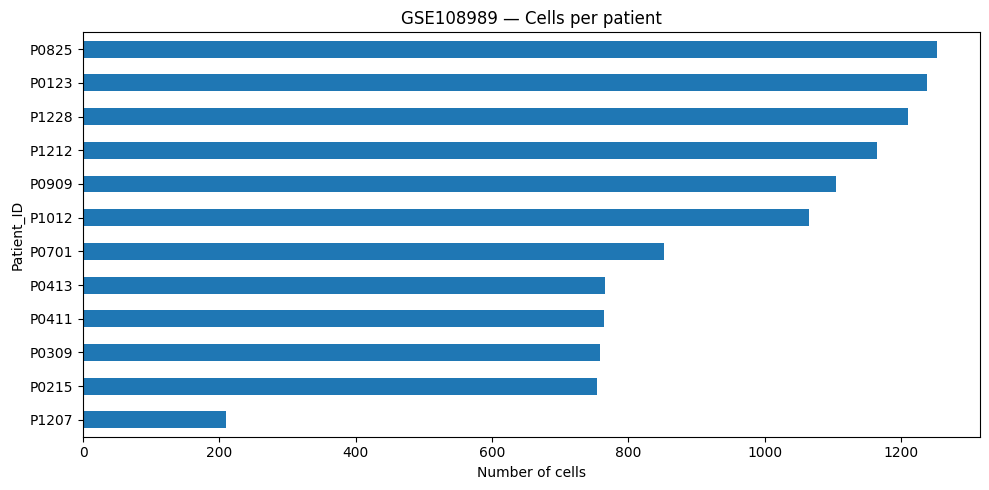

In [52]:
# Distribution of Patient_ID; numerical table followed by visualization
summary = count_and_percent(gse108989_metadata["Patient_ID"], "Patient_ID")
show_bar_table(summary, "Patient_ID", "GSE108989 — Cells per patient", figsize=(10, 5))

### 3.2 CD4/CD8 major groups and 20 annotated subclusters
Show the broad CD4/CD8 groups first, followed by the original 20 cluster labels.

CD4/CD8 cells: 8530


T_Cell_Type,CD4+,CD8+
Patient_ID,,
P0123,562,268
P0215,335,255
P0309,304,183
P0411,344,257
P0413,331,272
P0701,388,303
P0825,579,358
P0909,596,214
P1012,589,302


,T_Cell_Type,Cell_Count,Percentage
0,CD4+,4902,57.47
1,CD8+,3628,42.53


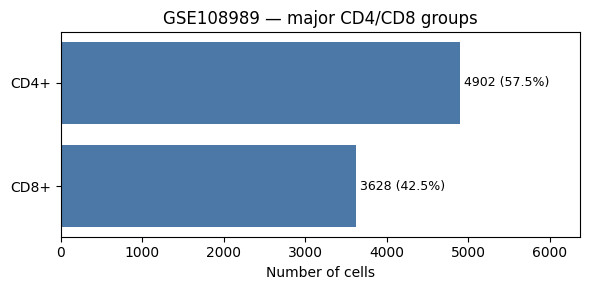

,Subcluster,Cell_Count,Percentage
0,CD4_C12-CTLA4,1319,15.46
1,CD8_C04-GZMK,840,9.85
2,CD8_C07-LAYN,831,9.74
3,CD8_C03-CX3CR1,773,9.06
4,CD4_C05-CXCR6,639,7.49
5,CD4_C02-ANXA1,509,5.97
6,CD4_C01-CCR7,472,5.53
7,CD8_C05-CD6,431,5.05
8,CD4_C10-FOXP3,365,4.28
9,CD8_C06-CD160,363,4.26


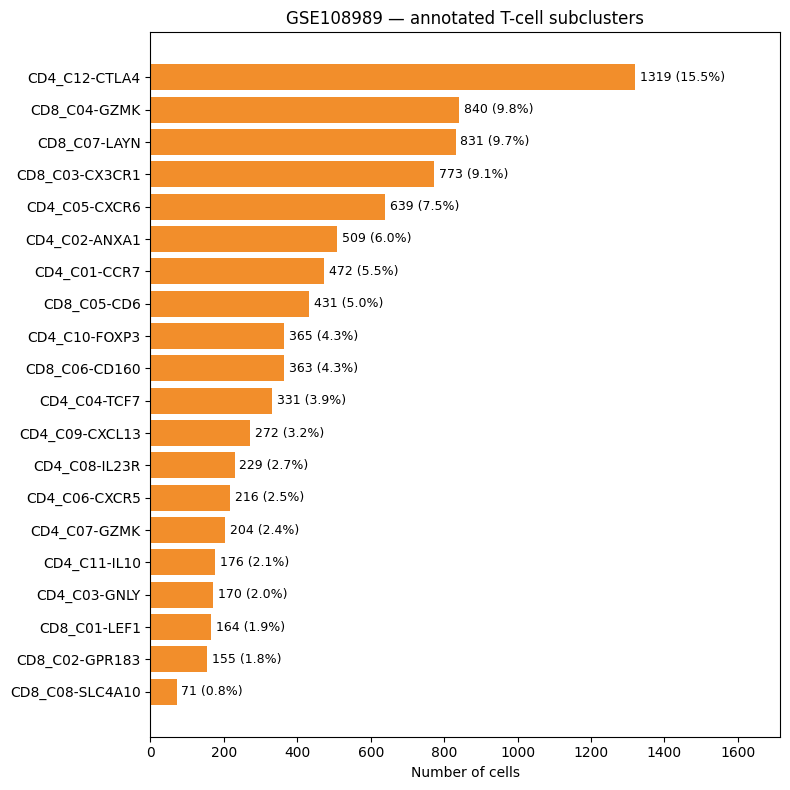

In [53]:

tcell_meta = gse108989_metadata[gse108989_metadata["T_Cell_Type"].notna()].copy()
print("CD4/CD8 cells:", len(tcell_meta))
display(pd.crosstab(tcell_meta["Patient_ID"], tcell_meta["T_Cell_Type"]))

major_summary = count_and_percent(tcell_meta["T_Cell_Type"], "T_Cell_Type")
show_compact_distribution(
    major_summary,
    "T_Cell_Type",
    "GSE108989 — major CD4/CD8 groups",
    figsize=(6, 3),
    color="#4C78A8"
)

subcluster_summary = count_and_percent(tcell_meta["majorCluster"], "Subcluster")
show_compact_distribution(
    subcluster_summary,
    "Subcluster",
    "GSE108989 — annotated T-cell subclusters",
    figsize=(8, 8),
    color="#F28E2B"
)


### 3.3 Tissue and FACS sorting categories
The first character of `sampleType` indicates tissue (N/P/T); the remaining characters identify the FACS sorting gate. A short table plus chart make this easier to read.

,Sample_Type,Cell_Count,Percentage
0,TTC,1806,16.21
1,TTR,1435,12.88
2,TTH,1370,12.30
3,PTC,1132,10.16
4,NTC,1072,9.62
5,PTH,997,8.95
6,NTH,953,8.56
7,PTR,912,8.19
8,NTR,406,3.65
9,TTY,304,2.73


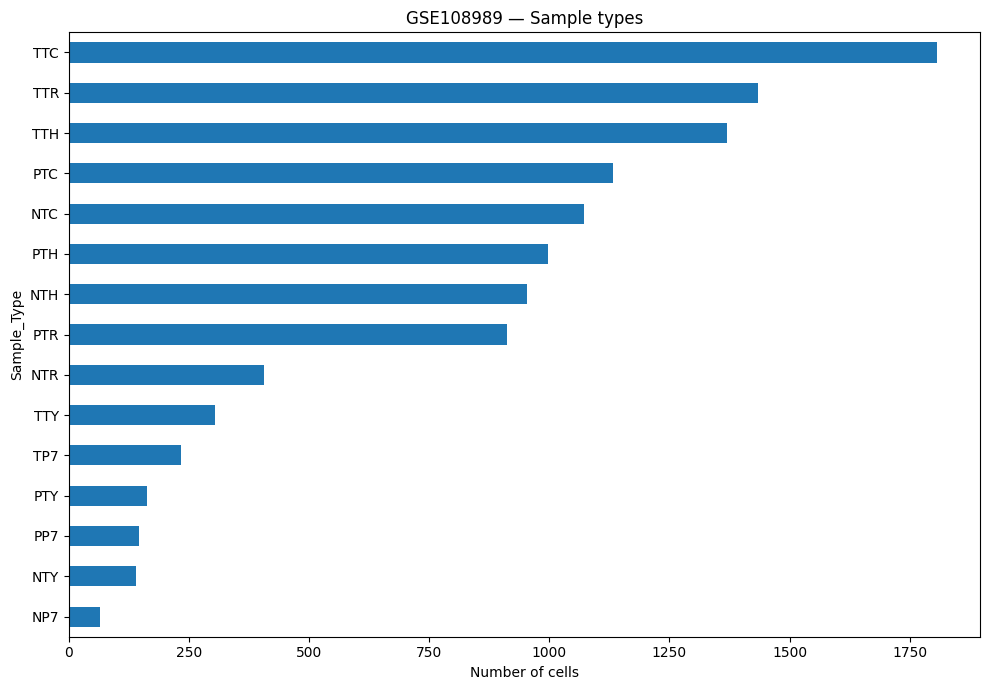

In [54]:
# Distribution of Sample_Type; numerical table followed by visualization
summary = count_and_percent(gse108989_metadata["sampleType"], "Sample_Type")
show_bar_table(summary, "Sample_Type", "GSE108989 — Sample types", figsize=(10, 7))

### 3.4 Patient-level subcluster proportions
Percentages are computed **within each patient and tissue**, and may be affected by the original FACS enrichment.

In [55]:
patient_tissue_counts = pd.crosstab(
    [tcell_meta["Patient_ID"], tcell_meta["Tissue"]], tcell_meta["majorCluster"]
)
patient_tissue_percentages = patient_tissue_counts.div(
    patient_tissue_counts.sum(axis=1), axis=0
).mul(100)
display(patient_tissue_percentages.round(1))


majorCluster                 CD4_C01-CCR7  CD4_C02-ANXA1  CD4_C03-GNLY  \
Patient_ID Tissue                                                        
P0123      Normal                     1.3            0.4           0.0   
           Peripheral Blood          33.0           19.2           4.4   
           Tumor                      0.0            0.5           0.0   
P0215      Normal                     0.7            0.0           0.0   
           Peripheral Blood          25.4           17.2           0.0   
           Tumor                      0.0            0.0           0.0   
P0309      Peripheral Blood          19.3           14.4           9.4   
           Tumor                      0.7            1.4           0.0   
P0411      Normal                     0.0            0.0           0.0   
           Peripheral Blood          19.1           14.2          19.1   
           Tumor                      0.0            0.0           0.0   
P0413      Normal                     0.0            0.8           0.8   
           Peripheral Blood          22.0           13.6           1.6   
           Tumor                      0.7            0.0           0.3   
P0701      Normal                     1.3            0.0           0.0   
           Peripheral Blood          19.2           21.5           2.3   
           Tumor                      0.0            1.6           0.0   
P0825      Normal                     0.0            0.9           0.4   
           Peripheral Blood          10.9           21.4           8.4   
           Tumor                      0.6            0.6           0.6   
P0909      Normal                    13.3            1.6           0.0   
           Peripheral Blood          17.9           25.9           3.3   
           Tumor                      0.0            0.0           0.0   
P1012      Peripheral Blood          15.7           36.2          10.8   
           Tumor                      0.0            1.1           0.2   
P1207      Peripheral Blood           0.0            0.0           0.0   
           Tumor                      0.0            0.0           0.0   
P1212      Normal                     1.4            0.6           0.0   
           Peripheral Blood          15.1           18.1           6.5   
           Tumor                      0.0            0.3           0.0   
P1228      Normal                     0.2            0.0           0.0   
           Peripheral Blood          12.1           17.9           8.9   
           Tumor                      0.0            0.3           0.0   

majorCluster                 CD4_C04-TCF7  CD4_C05-CXCR6  CD4_C06-CXCR5  \
Patient_ID Tissue                                                         
P0123      Normal                    18.2           12.6            4.3   
           Peripheral Blood           0.0            0.5            0.0   
           Tumor                      0.0           10.1            0.3   
P0215      Normal                     8.4           18.2            2.1   
           Peripheral Blood           0.6            0.0            0.0   
           Tumor                      1.4           12.2            0.7   
P0309      Peripheral Blood           0.0            0.0            0.0   
           Tumor                      6.0           13.0            4.9   
P0411      Normal                    13.0            3.9            3.2   
           Peripheral Blood           0.0            0.0            0.0   
           Tumor                      0.4            8.6            0.0   
P0413      Normal                     2.5           28.6            2.5   
           Peripheral Blood           0.0            0.0            0.0   
           Tumor                      0.3            8.5            1.0   
P0701      Normal                     7.5            1.9           10.1   
           Peripheral Blood           0.0            0.0            0.0   
           Tumor                      1.3            6.4   

### 3.5 Tissue composition overview
Display the observed subcluster percentages for Normal, Blood and Tumor.

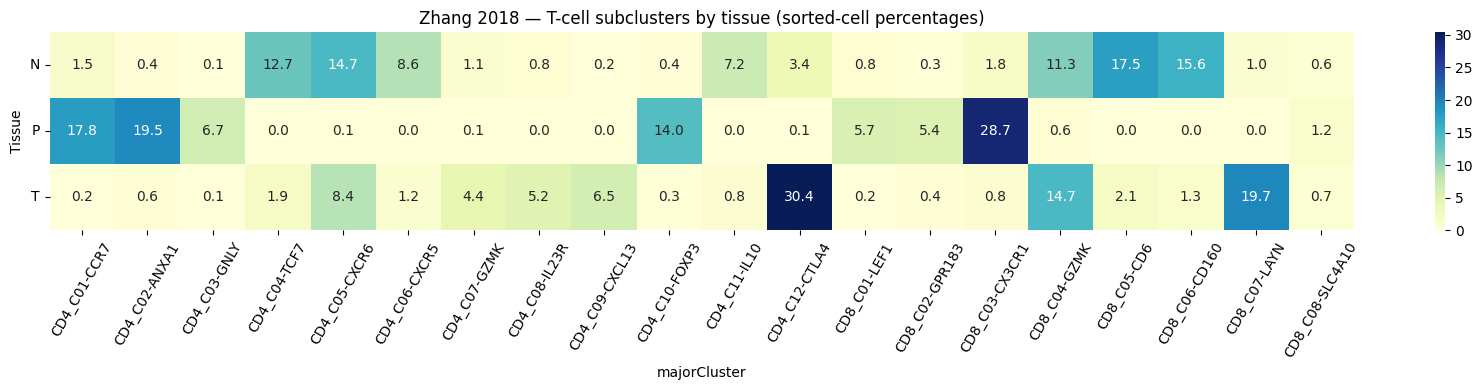

In [56]:
tissue_counts = pd.crosstab(tcell_meta["Tissue"], tcell_meta["majorCluster"])
tissue_percentages = tissue_counts.div(tissue_counts.sum(axis=1), axis=0).mul(100)

fig, ax = plt.subplots(figsize=(17, 4))

sns.heatmap(
    tissue_percentages.reindex(["Normal", "Peripheral Blood", "Tumor"]),
    cmap="YlGnBu", annot=True, fmt=".1f", ax=ax
)

ax.set_yticklabels(["N", "P", "T"], rotation=0)
ax.set_ylabel("Tissue")
ax.set_title("Zhang 2018 — T-cell subclusters by tissue (sorted-cell percentages)")
ax.tick_params(axis="x", rotation=60)

plt.tight_layout()
fig.savefig(RESULTS_DIR / "tcell_subtype_distribution_heatmap.png", dpi=250, bbox_inches="tight")
plt.show()

### 3.6 Tumor CD4/CD8 and subclusters by patient
Compare tumor-sampled cells within each patient; these are descriptive, sorting-dependent percentages.

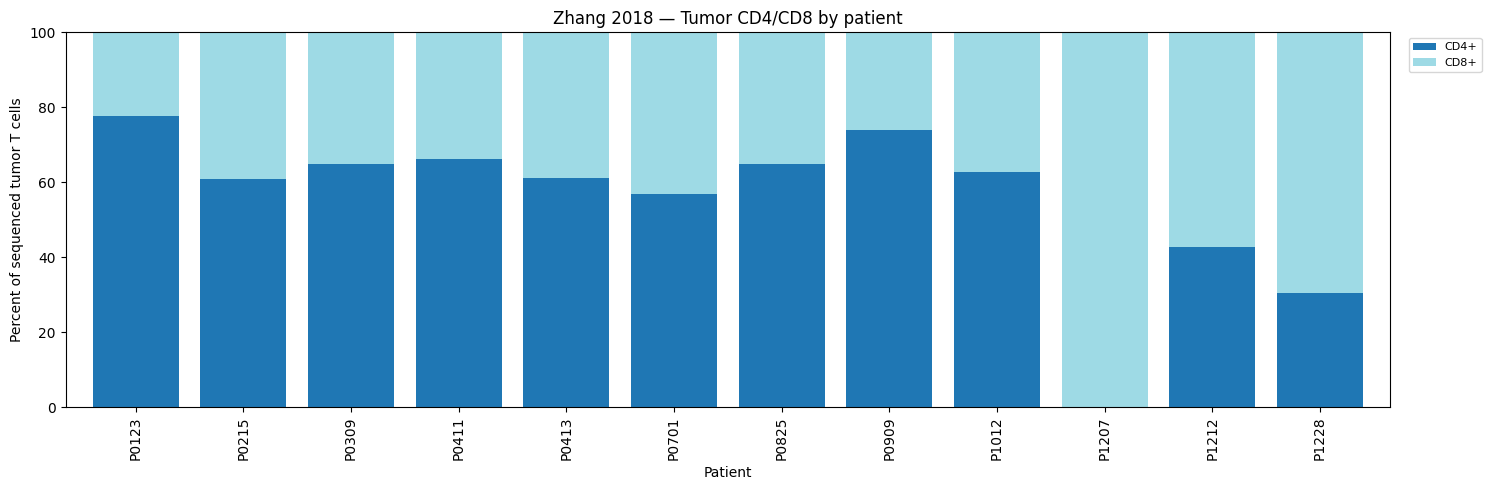

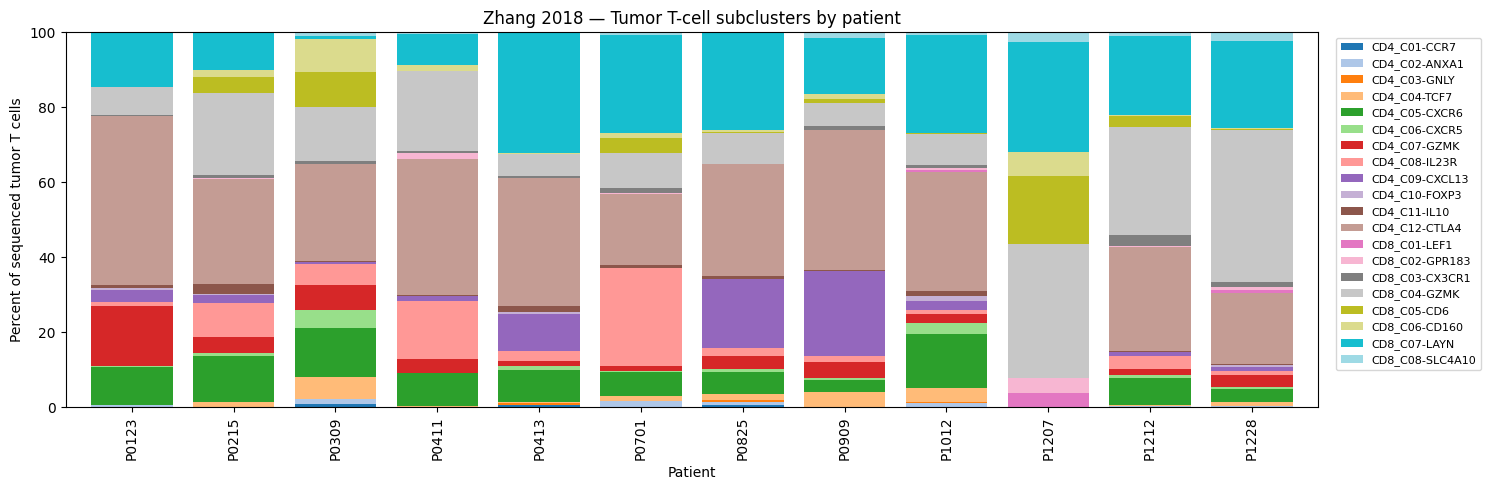

In [57]:
tumor_meta = tcell_meta[tcell_meta["Tissue"].eq("Tumor")].copy()
patient_ids = sorted(MSI_MAP)
major_counts = pd.crosstab(tumor_meta["Patient_ID"], tumor_meta["T_Cell_Type"]).reindex(
    index=patient_ids, columns=["CD4+", "CD8+"], fill_value=0
)
major_pct = major_counts.div(major_counts.sum(axis=1).replace(0, np.nan), axis=0).mul(100)
subcluster_counts = pd.crosstab(tumor_meta["Patient_ID"], tumor_meta["majorCluster"]).reindex(index=patient_ids, fill_value=0)
subcluster_pct = subcluster_counts.div(subcluster_counts.sum(axis=1).replace(0, np.nan), axis=0).mul(100)
for data, title, filename in [
    (major_pct, "Tumor CD4/CD8 by patient", "tumor_cd4_cd8_by_patient.png"),
    (subcluster_pct, "Tumor T-cell subclusters by patient", "tumor_tcell_subtypes_by_patient.png")
]:
    ax = data.plot(kind="bar", stacked=True, figsize=(15, 5), width=.8, colormap="tab20")
    ax.set_title("Zhang 2018 — " + title)
    ax.set_xlabel("Patient"); ax.set_ylabel("Percent of sequenced tumor T cells")
    ax.set_ylim(0, 100)
    ax.legend(bbox_to_anchor=(1.01, 1), loc="upper left", fontsize=8)
    plt.tight_layout(); plt.savefig(RESULTS_DIR / filename, dpi=250, bbox_inches="tight"); plt.show()


## 4. Expression matrices
Inspect gene counts and TPM without loading the full matrix into memory.

### 4.1 Gene counts and matrix previews

In [58]:
gse108989_count_preview = pd.read_csv(
    GSE108989_DIR / "GSE108989_CRC.TCell.S11138.count.txt.gz",
    sep="\t",
    nrows=5,
    compression="infer"
)

In [59]:
# Count genes in GSE108989 single-cell TPM matrix
tpm_file = GSE108989_DIR / "GSE108989_CRC.TCell.S11138.TPM.txt.gz"

gene_ids_tpm = pd.read_csv(
    tpm_file,
    sep="\t",
    usecols=[0],
    compression="gzip"
)

print("Number of gene rows:", len(gene_ids_tpm))
print("Number of unique gene IDs:", gene_ids_tpm.iloc[:, 0].nunique())

Number of gene rows: 23459
Number of unique gene IDs: 23459


In [60]:
# Inspect only a few rows to avoid loading full expression matrices
count_path_108989 = GSE108989_DIR / "GSE108989_CRC.TCell.S11138.count.txt.gz"
tpm_path_108989 = GSE108989_DIR / "GSE108989_CRC.TCell.S11138.TPM.txt.gz"
normalized_path_108989 = GSE108989_DIR / "GSE108989_CRC.TCell.S10805.norm.centered.txt.gz"

gse108989_count_preview = inspect_matrix_preview(count_path_108989, sep="\t", nrows=5)
inspect_matrix_preview(tpm_path_108989, sep="\t", nrows=3)
inspect_matrix_preview(normalized_path_108989, sep="\t", nrows=3)

File: GSE108989_CRC.TCell.S11138.count.txt.gz
Preview: 5 gene rows × 11140 columns
First column names: ['geneID', 'symbol', 'NP710-20180123', 'NP711-20180123', 'NP71-20180123', 'NP712-20180123']


,geneID,symbol,NP710-20180123,NP711-20180123,NP71-20180123,NP712-20180123
0,1,A1BG,0,0,27,0
1,10,NAT2,0,0,0,0
2,100,ADA,0,0,0,0
3,1000,CDH2,0,0,0,0
4,10000,AKT3,0,0,0,0


File: GSE108989_CRC.TCell.S11138.TPM.txt.gz
Preview: 3 gene rows × 11140 columns
First column names: ['geneID', 'symbol', 'NP710-20180123', 'NP711-20180123', 'NP71-20180123', 'NP712-20180123']


,geneID,symbol,NP710-20180123,NP711-20180123,NP71-20180123,NP712-20180123
0,1,A1BG,0,0,48.191757,0
1,10,NAT2,0,0,0.000000,0
2,100,ADA,0,0,0.000000,0


File: GSE108989_CRC.TCell.S10805.norm.centered.txt.gz
Preview: 3 gene rows × 10807 columns
First column names: ['geneID', 'geneSymbol', 'NP710-20180123', 'NP711-20180123', 'NP71-20180123', 'NP712-20180123']


,geneID,geneSymbol,NP710-20180123,NP711-20180123,NP71-20180123,NP712-20180123
0,1,A1BG,-0.515412,-0.515412,5.518178,-0.515412
1,100,ADA,-1.862244,-1.862244,-1.862244,-1.862244
2,10000,AKT3,-0.458035,-0.458035,-0.458035,-0.458035


,geneID,geneSymbol,NP710-20180123,NP711-20180123,NP71-20180123,NP712-20180123,NP713-20180123,NP714-20180123,NP718-20180123,NP720-20180123,...,PTC87-20161228,PTC89-20161228,PTC90-20161228,PTC91-20161228,PTC9-20161228,PTC92-20161228,PTC93-20161228,PTC94-20161228,PTC95-20161228,PTC96-20161228
0,1,A1BG,-0.515412,-0.515412,5.518178,-0.515412,4.825216,-0.515412,-0.515412,-0.515412,...,-0.710540,-0.710540,-0.710540,-0.710540,2.482191,2.511708,-0.710540,3.289508,-0.710540,-0.710540
1,100,ADA,-1.862244,-1.862244,-1.862244,-1.862244,-1.862244,4.373298,-1.862244,-1.862244,...,-1.291556,5.078320,-1.291556,-1.291556,-1.291556,7.729957,0.494275,-1.291556,6.638120,-1.291556
2,10000,AKT3,-0.458035,-0.458035,-0.458035,-0.458035,-0.458035,-0.458035,-0.458035,-0.458035,...,0.097423,-0.879971,-0.879971,-0.879971,7.155262,-0.879971,1.679848,-0.879971,-0.879971,-0.879971


In [61]:
# The first two columns of the count matrix are gene annotations: geneID and symbol.
print("First count-matrix columns:", gse108989_count_preview.columns[:5].tolist())
metadata_cells_108989 = set(gse108989_metadata["UniqueCell_ID"].dropna().astype(str))
expression_cells_108989 = set(gse108989_count_preview.columns[2:].astype(str))
shared_cells_108989 = metadata_cells_108989 & expression_cells_108989

matching_summary_108989 = pd.DataFrame({
    "Metric": ["Metadata cell IDs", "Count matrix cell IDs", "Shared IDs",
               "Metadata IDs matched (%)", "Matrix IDs matched (%)"],
    "Value": [len(metadata_cells_108989), len(expression_cells_108989),
              len(shared_cells_108989),
              round(100 * len(shared_cells_108989) / len(metadata_cells_108989), 2),
              round(100 * len(shared_cells_108989) / len(expression_cells_108989), 2)]
})
display(matching_summary_108989)
print("Example matched cell IDs:", sorted(shared_cells_108989)[:5])

First count-matrix columns: ['geneID', 'symbol', 'NP710-20180123', 'NP711-20180123', 'NP71-20180123']


,Metric,Value
0,Metadata cell IDs,11138.0
1,Count matrix cell IDs,11138.0
2,Shared IDs,11138.0
3,Metadata IDs matched (%),100.0
4,Matrix IDs matched (%),100.0


Example matched cell IDs: ['NP71-20180123', 'NP710-20180123', 'NP711-20180123', 'NP712-20180123', 'NP713-20180123']


### 4.2 Bulk RNA-seq / mutation files (optional)
List supplementary bulk and exome files without mixing them into the single-cell statistical tests.

In [62]:
# Explore bulk RNA-seq and exome mutation files

bulk_files = {
    "Bulk Count": "GSE108989_CRC.bulk.S12.count.tab.gz",
    "Bulk TPM": "GSE108989_CRC.bulk.S12.TPM.tab.gz",
    "Exome Mutation": "GSE108989_CRC.bulk.exome.mutation.tab.gz"
}

for name, filename in bulk_files.items():

    df = pd.read_csv(
        GSE108989_DIR / filename,
        sep="\t",
        nrows=5,
        compression="infer"
    )

    print(f"\n{'=' * 50}")
    print(name)
    print("Preview shape:", df.shape)
    print("Number of columns:", len(df.columns))
    print("Columns:", df.columns.tolist())

    display(df.head())


Bulk Count
Preview shape: (5, 14)
Number of columns: 14
Columns: ['geneID', 'symbol', 'P0123', 'P0215', 'P0309', 'P0411', 'P0413', 'P0701', 'P0825', 'P0909', 'P1012', 'P1207', 'P1212', 'P1228']


,geneID,symbol,P0123,P0215,P0309,P0411,P0413,P0701,P0825,P0909,P1012,P1207,P1212,P1228
0,1,A1BG,181,186,56,144,145,34,74,94,166,53,126,143
1,10,NAT2,0,51,268,208,2,930,1,590,1,18,0,3
2,100,ADA,342,630,89,206,325,317,213,562,928,61,200,469
3,1000,CDH2,54,623,142,86,635,9,28,102,296,68,70,199
4,10000,AKT3,472,925,805,1038,2886,211,679,828,1938,415,868,1504



Bulk TPM
Preview shape: (5, 14)
Number of columns: 14
Columns: ['geneID', 'symbol', 'P0123', 'P0215', 'P0309', 'P0411', 'P0413', 'P0701', 'P0825', 'P0909', 'P1012', 'P1207', 'P1212', 'P1228']


,geneID,symbol,P0123,P0215,P0309,P0411,P0413,P0701,P0825,P0909,P1012,P1207,P1212,P1228
0,1,A1BG,4.456907,2.918406,1.420063,3.539366,3.792435,0.781577,2.138246,2.214791,2.467034,1.751027,4.756861,3.996514
1,10,NAT2,0.000000,2.446802,20.780220,15.632275,0.159947,65.368957,0.088353,42.506240,0.045443,1.818383,0.000000,0.256367
2,100,ADA,22.136244,25.983410,5.932426,13.309235,22.343767,19.154679,16.178135,34.806793,36.252496,5.297484,19.847363,34.454109
3,1000,CDH2,1.197103,8.800422,3.241832,1.903024,14.952252,0.186259,0.728395,2.163654,3.960423,2.022594,2.379199,5.007041
4,10000,AKT3,6.375634,7.961609,11.198034,13.995447,41.406917,2.660735,10.762723,10.701917,15.799642,7.521275,17.976125,23.057890



Exome Mutation
Preview shape: (5, 76)
Number of columns: 76
Columns: ['patient', 'CHROM', 'POS', 'ID', 'REF', 'ALT', 'QUAL', 'FILTER', 'QSS', 'TQSS', 'NT', 'QSS_NT', 'TQSS_NT', 'SGT', 'SOMATIC', 'NORMAL_FREQ', 'TUMOR_FREQ', 'Func', 'Gene', 'GeneDetail', 'ExonicFunc', 'AAChange', 'cytoband', 'genomicSuperDups', 'phastConsElements46way', 'evofold', 'wgRna', 'targetScanS', 'tfbsConsSites', 'esp6500siv2_all', '1000g2014oct_all', '1000g2014oct_afr', '1000g2014oct_eas', '1000g2014oct_eur', 'avsnp142', 'SIFT_score', 'SIFT_pred', 'Polyphen2_HDIV_score', 'Polyphen2_HDIV_pred', 'Polyphen2_HVAR_score', 'Polyphen2_HVAR_pred', 'LRT_score', 'LRT_pred', 'MutationTaster_score', 'MutationTaster_pred', 'MutationAssessor_score', 'MutationAssessor_pred', 'FATHMM_score', 'FATHMM_pred', 'RadialSVM_score', 'RadialSVM_pred', 'LR_score', 'LR_pred', 'VEST3_score', 'CADD_raw', 'CADD_phred', 'GERP++_RS', 'phyloP46way_placental', 'phyloP100way_vertebrate', 'SiPhy_29way_logOdds', 'gerp++elem', 'gerp++gt2', 'cosmic

,patient,CHROM,POS,ID,REF,ALT,QUAL,FILTER,QSS,TQSS,...,OMIM_DAVID,CancerGeneCensus,BertVogelstein125,Predisposition,DriverCNA,Rearrangement,GO_BP,GO_CC,GO_MF,REACTOME_PATHWAY
0,P1207T,1,1888083,.,G,A,.,PASS,304,-,...,.,.,.,.,.,.,.,.,.,.
1,P1207T,1,15650938,.,G,T,.,PASS,105,-,...,.,.,.,.,.,.,.,.,.,.
2,P1207T,1,53363188,.,T,A,.,PASS,46,-,...,.,.,.,.,.,.,GO:0055114~oxidation-reduction process;GO:0019...,GO:0005739~mitochondrion,GO:0016835~carbon-oxygen lyase activity;GO:001...,.
3,P1207T,1,93620290,.,C,T,.,PASS,26,-,...,.,.,.,.,.,.,GO:0033036~macromolecule localization;GO:00901...,GO:0005783~endoplasmic reticulum;GO:0005793~en...,.,R-HSA-3238698:R-HSA-3238698
4,P1207T,1,103548536,.,A,G,.,PASS,24,-,...,228520~Fibrochondrogenesis 1;603932~Lumbar dis...,.,.,.,.,.,GO:0042471~ear morphogenesis;GO:0001501~skelet...,GO:0005576~extracellular region;GO:0005783~end...,GO:0005198~structural molecule activity;GO:006...,R-HSA-1650814:R-HSA-1650814;R-HSA-3000171:R-HS...


## 5. t-SNE visualizations

We compute one embedding from all 8,530 annotated T cells using the **2,000 highest-variance genes across all genes** (not the top 30 genes from each file chunk), then PCA and t-SNE. Every figure reuses these coordinates. This is a standard exploratory visualization, not an exact reproduction of the published figure.

### 5.1 Reuse the updated coordinates if available

The new filename ensures that the older t-SNE (with block-wise variable-gene selection) is not reused accidentally.

In [63]:
tsne_file = RESULTS_DIR / "tsne_coordinates_hvg2000.csv"
if tsne_file.exists():
    coords = pd.read_csv(tsne_file)
    required = {"UniqueCell_ID", "tSNE_1", "tSNE_2"}
    assert required.issubset(coords.columns), "Saved t-SNE file lacks required columns."
    assert coords["UniqueCell_ID"].is_unique, "Duplicate cell IDs in t-SNE file."
    assert set(coords["UniqueCell_ID"].astype(str)) == set(tcell_meta["UniqueCell_ID"].astype(str)),         "Saved coordinates do not match the selected 2018 T cells."
    tsne_meta_108989 = tcell_meta.merge(
        coords[["UniqueCell_ID", "tSNE_1", "tSNE_2"]],
        on="UniqueCell_ID", validate="one_to_one"
    )
    print("Loaded updated t-SNE:", tsne_file, tsne_meta_108989.shape)
else:
    print("Updated t-SNE not found. Run the next cell to calculate it once.")

Updated t-SNE not found. Run the next cell to calculate it once.


### 5.1.1 Compute PCA + t-SNE with **global** variable-gene selection

Read the TPM matrix in manageable chunks, but retain the 2,000 genes with the highest variance **across the entire dataset**. Each gene's variance is calculated across all 8,530 selected cells, not within an arbitrary chunk. Only this cell requires t-SNE computation.

In [64]:
if not tsne_file.exists():
    from sklearn.decomposition import PCA
    from sklearn.manifold import TSNE

    selected_cells = tcell_meta["UniqueCell_ID"].astype(str).tolist()
    n_cells = len(selected_cells)
    tpm_file = GSE108989_DIR / "GSE108989_CRC.TCell.S11138.TPM.txt.gz"
    header = pd.read_csv(tpm_file, sep="\t", nrows=0).columns.tolist()
    gene_column = header[0]
    missing = set(selected_cells) - set(header)
    assert not missing, f"{len(missing)} selected cells are missing from the TPM file."

    # Select the *global* top 2,000 high-variance genes, with modest RAM usage.
    n_top = 2000
    best_vars = np.empty(0, dtype=np.float64)
    best_expr = np.empty((0, n_cells), dtype=np.float32)
    genes_processed = 0

    for chunk in pd.read_csv(
        tpm_file, sep="\t", usecols=[gene_column] + selected_cells,
        chunksize=250, compression="infer"
    ):
        values = np.log1p(
            chunk[selected_cells].fillna(0).to_numpy(dtype=np.float32)
        )
        variances = values.var(axis=1, dtype=np.float64)
        variances[~np.isfinite(variances)] = -np.inf
        all_vars = np.concatenate([best_vars, variances])
        all_expr = np.vstack([best_expr, values])
        keep = (np.argpartition(all_vars, -n_top)[-n_top:]
                if len(all_vars) > n_top else np.arange(len(all_vars)))
        best_vars, best_expr = all_vars[keep], all_expr[keep]
        genes_processed += len(chunk)

    assert len(best_vars) >= 30, "Too few genes available for PCA."
    assert np.isfinite(best_vars).all(), "Non-finite expression variances detected."
    X = best_expr[np.argsort(best_vars)[::-1]].T.copy()
    print(f"Processed {genes_processed:,} genes; selected {X.shape[1]:,} globally variable genes")
    print("Cell-by-gene matrix:", X.shape)

    X_pca = PCA(n_components=30, random_state=42).fit_transform(X)
    X_tsne = TSNE(
        n_components=2, perplexity=30, init="pca",
        learning_rate="auto", random_state=42
    ).fit_transform(X_pca)

    coords = pd.DataFrame({
        "UniqueCell_ID": selected_cells,
        "tSNE_1": X_tsne[:, 0],
        "tSNE_2": X_tsne[:, 1]
    })
    coords.to_csv(tsne_file, index=False)
    tsne_meta_108989 = tcell_meta.merge(coords, on="UniqueCell_ID", validate="one_to_one")
    print("Saved new coordinates:", tsne_file)
else:
    print("Using the existing global-HVG t-SNE coordinates.")

Processed 23,459 genes; selected 2,000 globally variable genes
Cell-by-gene matrix: (8530, 2000)
Saved new coordinates: /cfs/earth/scratch/suereser/crc_singlecell/results/GSE108989/tsne_coordinates_hvg2000.csv


### 5.2 Shared plotting function
One helper produces consistently styled t-SNE figures without duplicated plotting code.

In [65]:
plot_data = tsne_meta_108989.copy()
plot_data["MSI_Status"] = plot_data["Patient_ID"].map(MSI_MAP)
plot_data["Tissue"] = plot_data["sampleType"].astype(str).str[0].map({"N":"Normal", "P":"Peripheral Blood", "T":"Tumor"})
plot_data["T_Cell_Type"] = plot_data["majorCluster"].astype(str).str[:3].map({"CD4":"CD4+", "CD8":"CD8+"})
assert plot_data["MSI_Status"].notna().all()

def tsne_plot(data, hue, title, filename, style=None, figsize=(12, 7), palette=None):
    fig, ax = plt.subplots(figsize=figsize)
    sns.scatterplot(data=data, x="tSNE_1", y="tSNE_2", hue=hue, style=style,
                    palette=palette, s=13, alpha=.75, linewidth=0, ax=ax)
    ax.set_title(title)
    ax.legend(bbox_to_anchor=(1.01, 1), loc="upper left", fontsize=8, markerscale=1.7)
    plt.tight_layout()
    fig.savefig(RESULTS_DIR / filename, dpi=250, bbox_inches="tight")
    plt.show()

def tsne_panels(plot_data, panel_col, color_col, title, filename, palette=None):
    panel_order = [x for x in plot_data[panel_col].dropna().unique()]
    color_order = [x for x in plot_data[color_col].dropna().unique()]

    fig, axes = plt.subplots(
        1, len(panel_order),
        figsize=(7 * len(panel_order) + 3, 5),
        sharex=True, sharey=True
    )

    if len(panel_order) == 1:
        axes = [axes]

    legend_handles, legend_labels = None, None

    for ax, group in zip(axes, panel_order):
        sub = plot_data[plot_data[panel_col] == group].copy()

        
        ax.scatter(
            plot_data["tSNE_1"], plot_data["tSNE_2"],
            s=6, c="lightgray", alpha=0.25, linewidth=0
        )

        
        sns.scatterplot(
            data=sub,
            x="tSNE_1", y="tSNE_2",
            hue=color_col,
            hue_order=color_order,
            palette=palette,
            s=10,
            alpha=0.9,
            linewidth=0,
            ax=ax,
            legend=True
        )

        ax.set_title(f"{group} (n={len(sub):,})")
        ax.set_xlabel("tSNE_1")
        ax.set_ylabel("tSNE_2")

        
        handles, labels = ax.get_legend_handles_labels()
        if legend_handles is None:
            legend_handles, legend_labels = handles, labels

        
        if ax.get_legend() is not None:
            ax.get_legend().remove()

    
    if color_col == "T_Cell_Type":
        legend_title = "T Cell Type"
    elif color_col == "majorCluster":
        legend_title = "T Cell Subtypes"
    else:
        legend_title = color_col

    
    fig.legend(
        legend_handles, legend_labels,
        title=legend_title,
        loc="center left",
        bbox_to_anchor=(1.02, 0.5),
        frameon=True,
        fontsize=9,
        title_fontsize=10
    )

    fig.suptitle(title, fontsize=15)
    plt.tight_layout(rect=[0, 0, 0.86, 0.95])   # sağda legend için yer bırak
    fig.savefig(RESULTS_DIR / filename, dpi=300, bbox_inches="tight")
    plt.show()

### 5.3 Single-variable t-SNE figures
Start with MSI status, tissue, CD4/CD8 major group and all 20 subclusters separately.

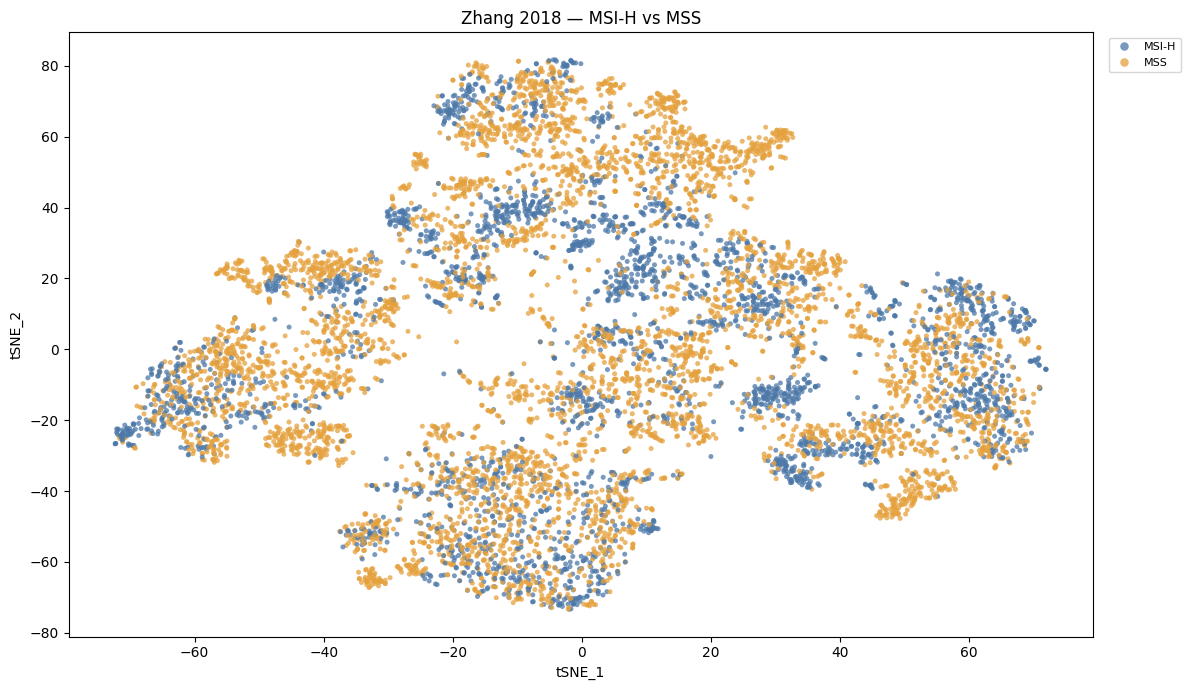

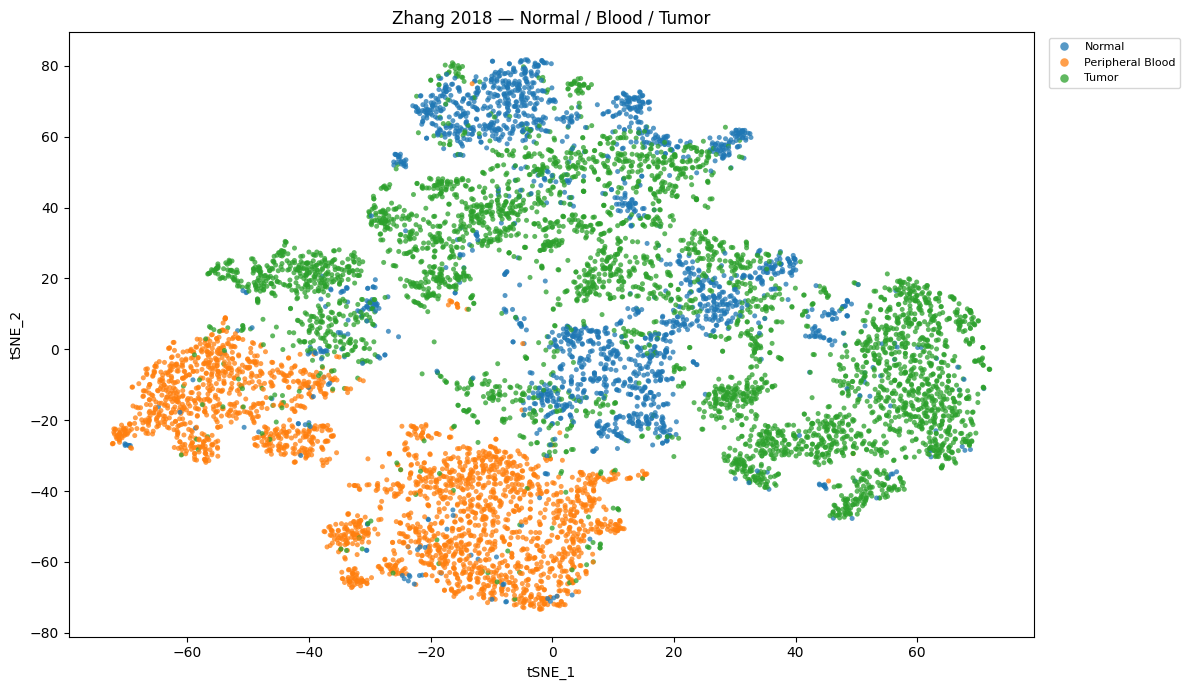

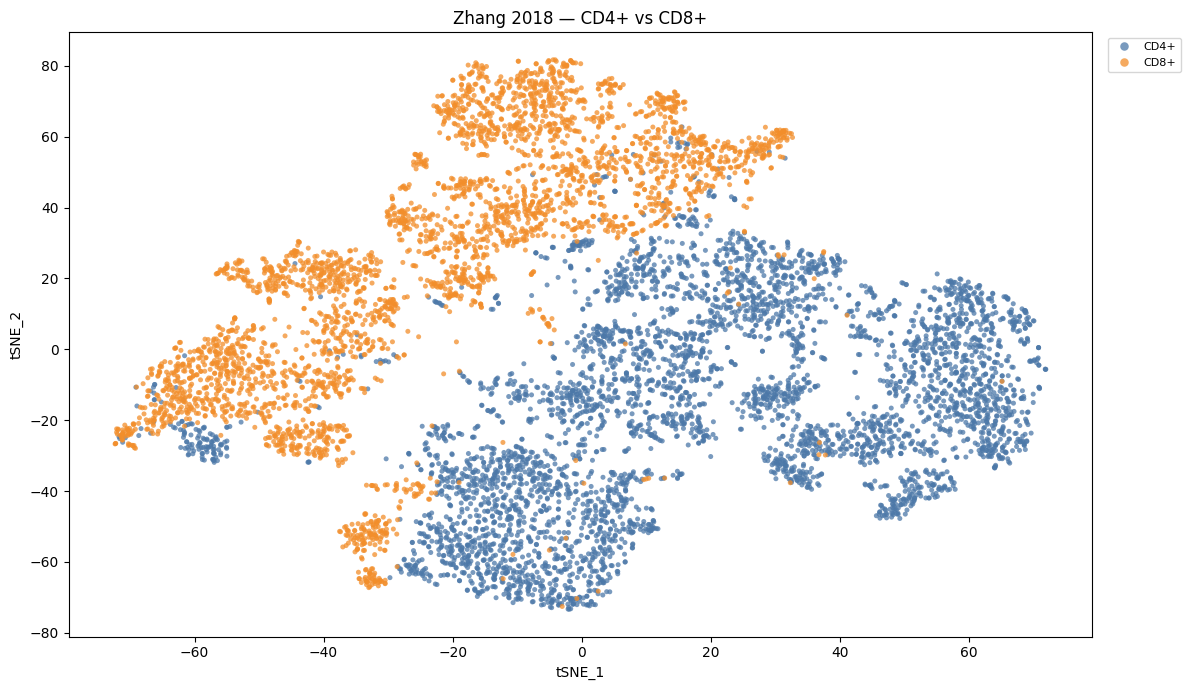

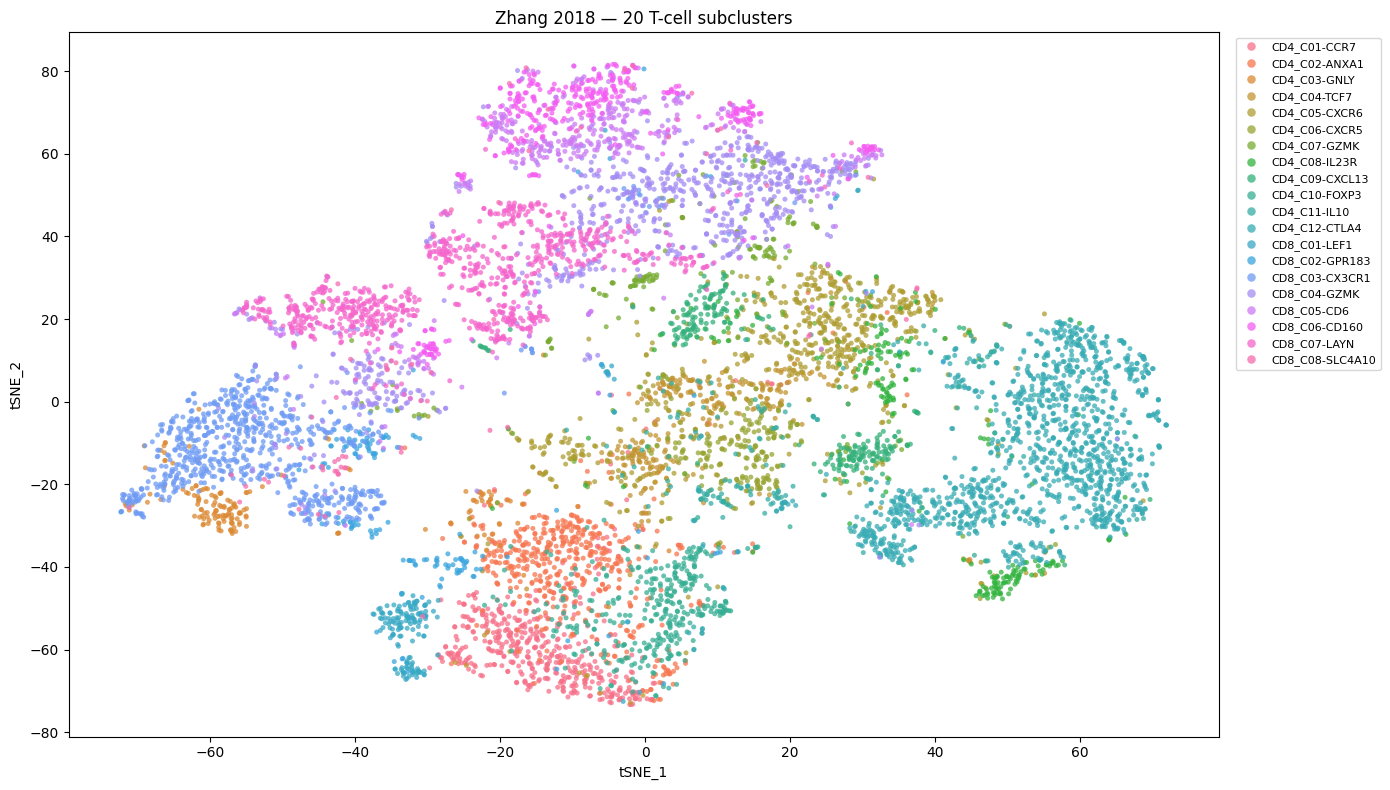

In [66]:
tsne_plot(plot_data, "MSI_Status", "Zhang 2018 — MSI-H vs MSS", "tsne_2018_msi_only.png", palette={"MSI-H":"#4C78A8", "MSS":"#E5A13D"})
tsne_plot(plot_data, "Tissue", "Zhang 2018 — Normal / Blood / Tumor", "tsne_2018_tissue_only.png")
tsne_plot(plot_data, "T_Cell_Type", "Zhang 2018 — CD4+ vs CD8+", "tsne_2018_major_only.png", palette={"CD4+":"#4C78A8", "CD8+":"#F28E2B"})
tsne_plot(plot_data, "majorCluster", "Zhang 2018 — 20 T-cell subclusters", "tsne_2018_subclusters_only.png", figsize=(14, 8))


### 5.4 Separate tissue and MSI panels
Show each tissue and MSI group against the same gray-background embedding for easier reading.

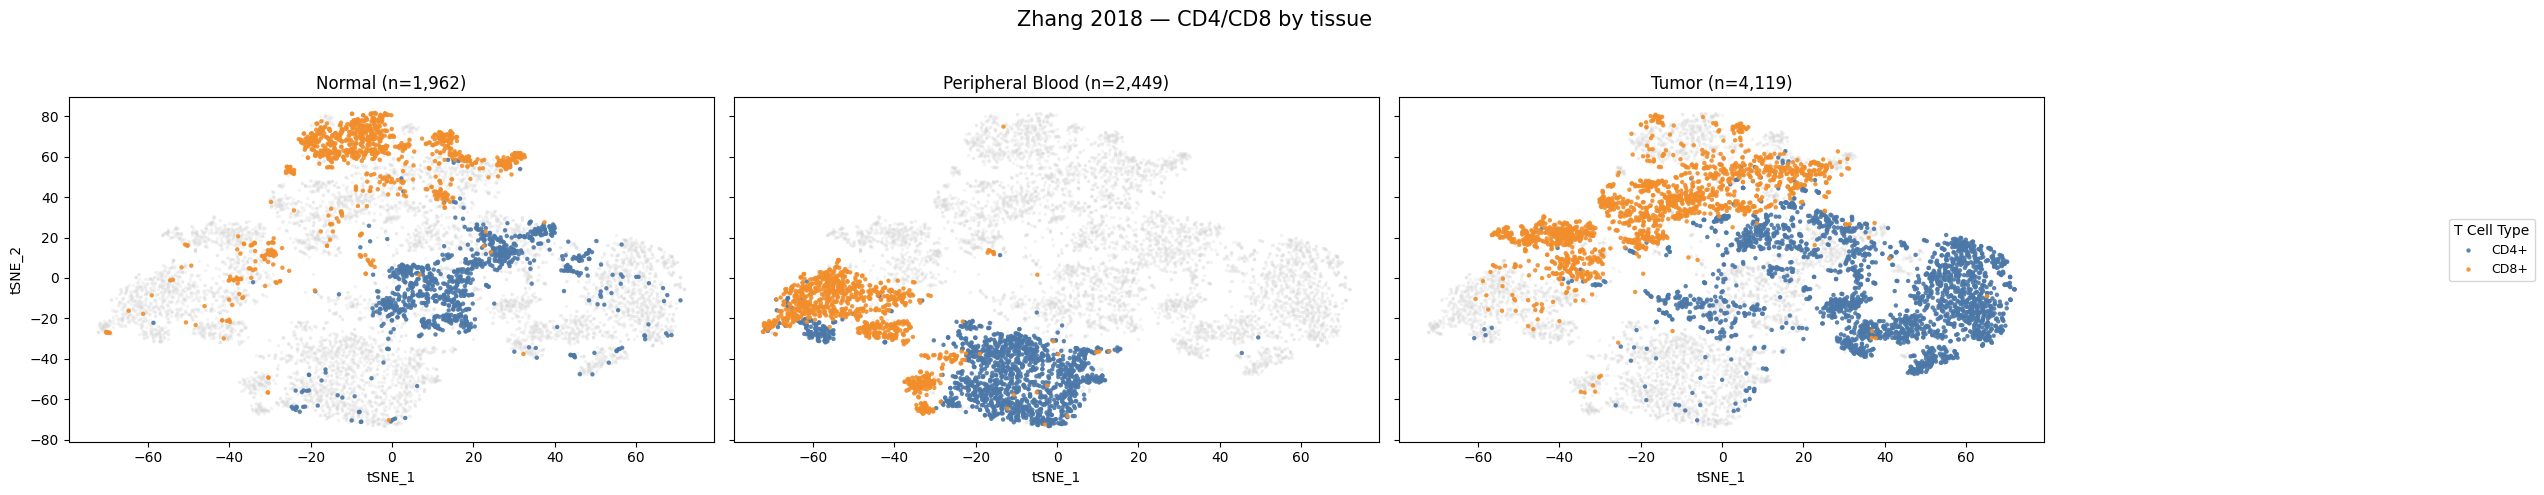

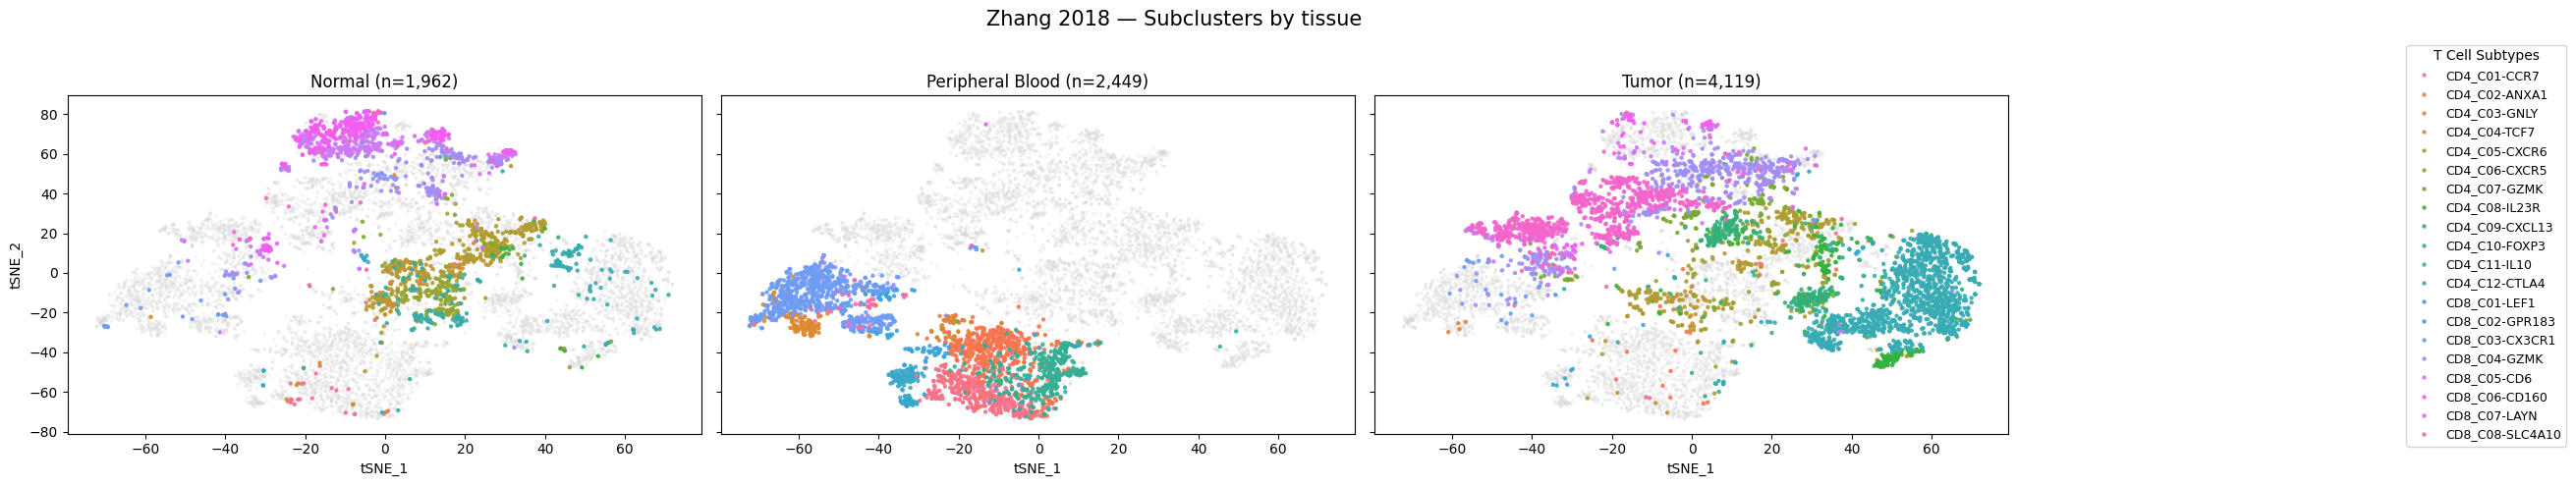

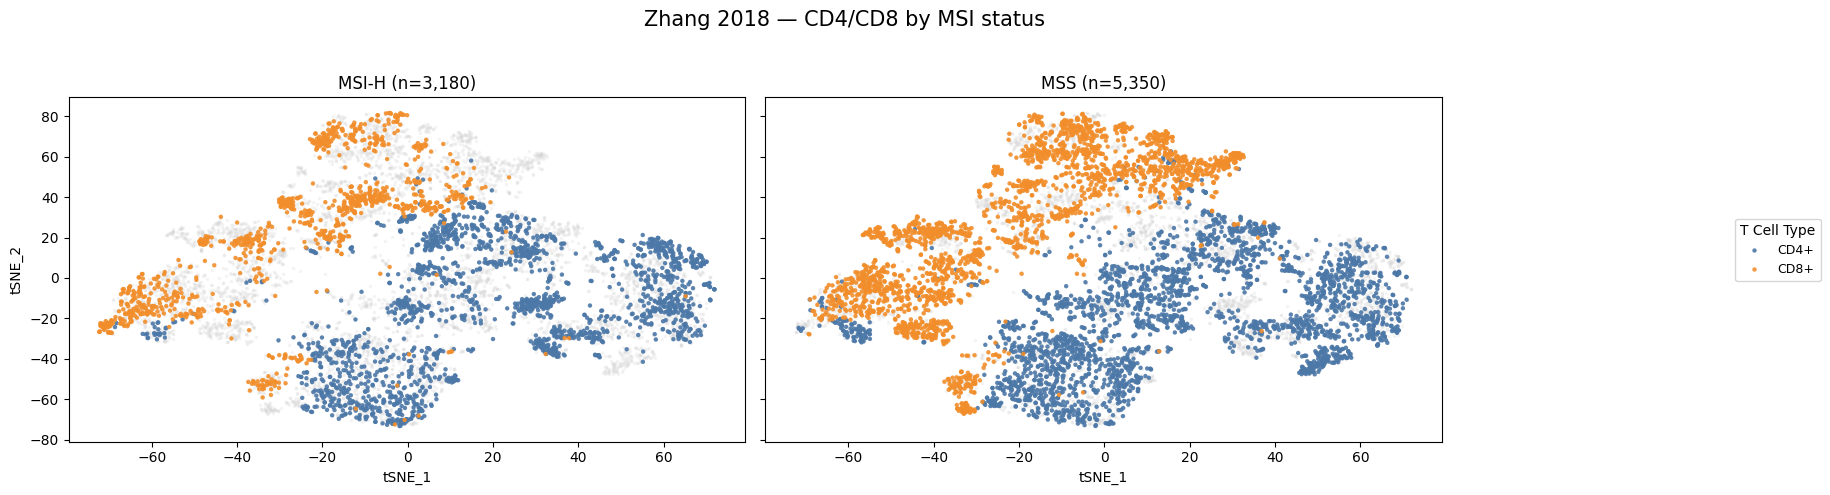

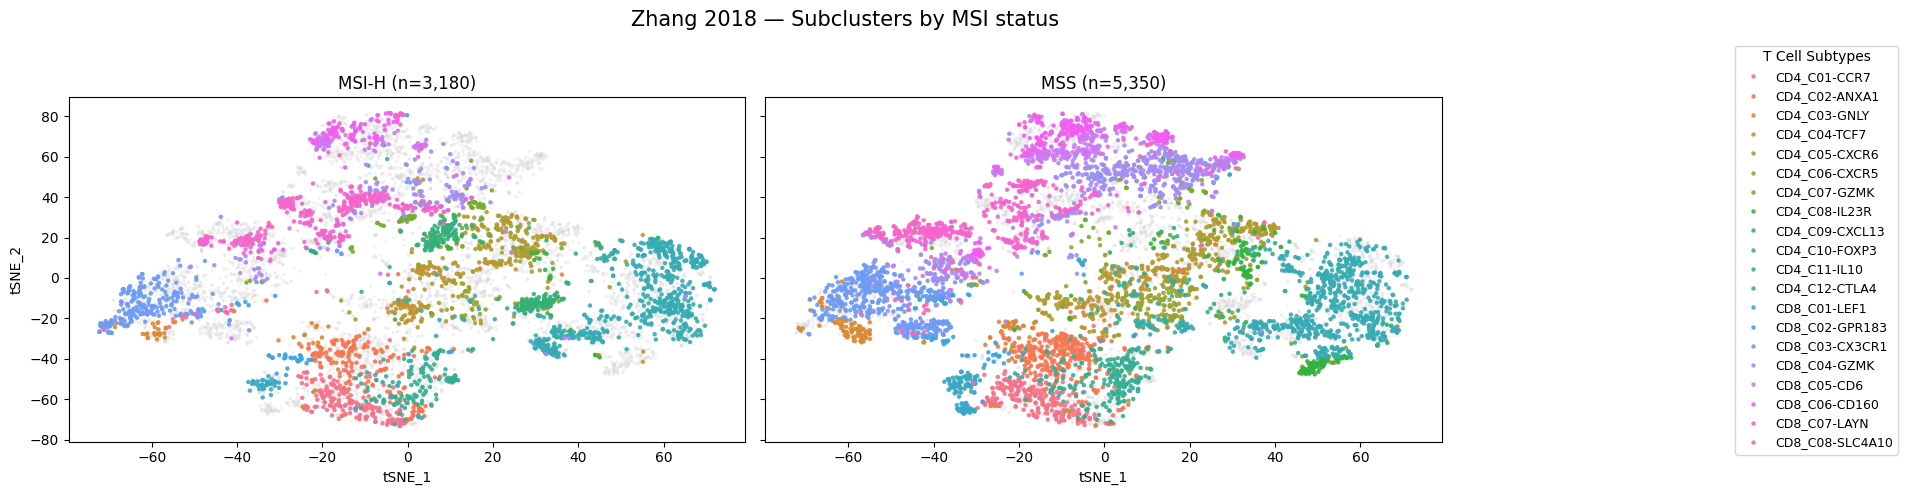

In [67]:
tsne_panels(plot_data, "Tissue", "T_Cell_Type", "Zhang 2018 — CD4/CD8 by tissue", "tsne_2018_tissue_panels_major.png", palette={"CD4+":"#4C78A8", "CD8+":"#F28E2B"})
tsne_panels(plot_data, "Tissue", "majorCluster", "Zhang 2018 — Subclusters by tissue", "tsne_2018_tissue_panels_subclusters.png")
tsne_panels(plot_data, "MSI_Status", "T_Cell_Type", "Zhang 2018 — CD4/CD8 by MSI status", "tsne_2018_msi_panels_major.png", palette={"CD4+":"#4C78A8", "CD8+":"#F28E2B"})
tsne_panels(plot_data, "MSI_Status", "majorCluster", "Zhang 2018 — Subclusters by MSI status", "tsne_2018_msi_panels_subclusters.png")


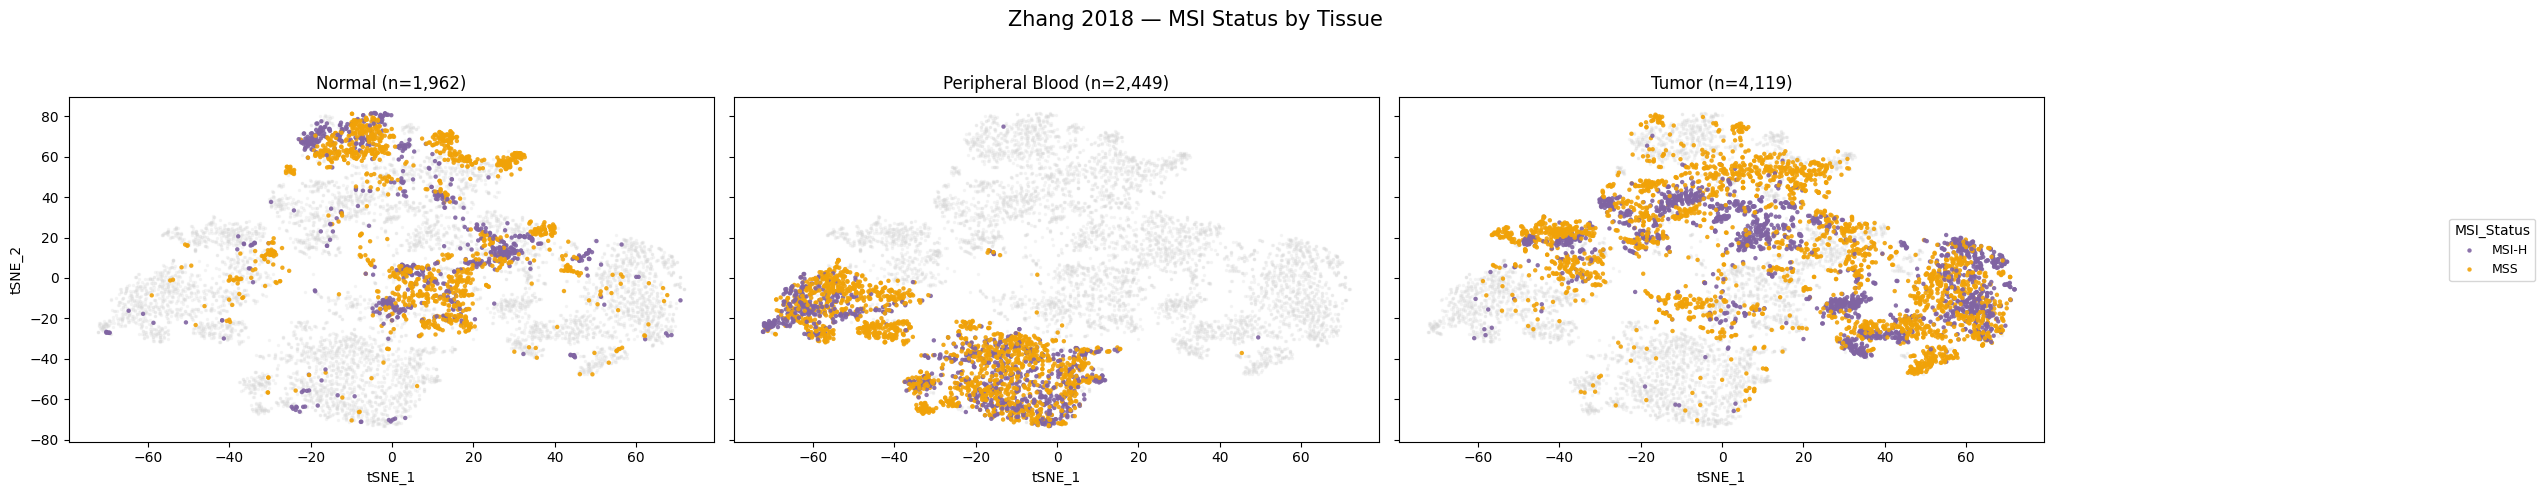

In [68]:
# MSI-H vs MSS distribution across tissues
tsne_panels(
    plot_data,
    "Tissue",
    "MSI_Status",
    "Zhang 2018 — MSI Status by Tissue",
    "tsne_2018_msi_status_by_tissue.png",
    palette={"MSI-H": "#8064A2", "MSS": "#F1A208"}
)

## 6. Statistics — MSI-H vs MSS (tumor T cells)

**Research question:** Are the percentages of sampled tumor T-cell populations different between MSI-H and MSS patients?

- **Independent observation:** One patient. Use all eligible Zhang 2018 patients (4 MSI-H and 8 MSS); an absent lineage is missing data, not a 0% subtype measurement.
- **Major groups:** CD4+ and CD8+ percentages relative to all sampled CD4+ + CD8+ tumor cells from that patient.
- **20 subclusters:** Each subtype percentage relative to that patient's sampled tumor CD4+ or CD8+ lineage (different denominator from major groups).
- **Mann–Whitney U H0:** The two patient-level percentage distributions are the same. **H1:** They differ (two-sided). This is a rank/distribution comparison, not a mean test.
- **Welch t-test H0:** The two groups' mean patient-level percentages are equal. **H1:** Their means differ (two-sided). Welch permits unequal variances but can be sensitive to outliers and skew with n=4 vs 8.
- **Multiple testing:** Benjamini–Hochberg adjustment separately within each family (2 major groups or 20 subclusters) and test method. The CD4/CD8 major percentages are mathematically complementary, not independent findings.
- **Limitations:** Small patient groups, FACS enrichment, percentage dependence, and (for CD4 subclusters) one MSS patient lacking CD4 tumor cells. No test creates additional independent patients. These are exploratory associations, not causal evidence.

### 6.1 Prepare patient-level tumor percentages
For major groups use CD4/(CD4+CD8) and CD8/(CD4+CD8). For subclusters use the corresponding **CD4 or CD8 total** as denominator, matching the biological lineage being examined.

In [69]:
from scipy.stats import mannwhitneyu
from statsmodels.stats.multitest import multipletests

# Check all 12 patient IDs against the paper and the actual tumor samples.
patient_ids_2018 = sorted(MSI_MAP)
available_tumor_patients = sorted(tumor_meta["Patient_ID"].dropna().unique())
print("2018 patients in metadata:", len(patient_ids_2018))
print("Patients with sampled tumor T cells:", len(available_tumor_patients))
print("MSI-H:", sum(MSI_MAP[p] == "MSI-H" for p in available_tumor_patients))
print("MSS:", sum(MSI_MAP[p] == "MSS" for p in available_tumor_patients))
assert set(available_tumor_patients) == set(patient_ids_2018), (
    "Some patients have no annotated tumor T cells; verify the actual group sizes."
)

# Already defined in Section 3.6: major_counts, subcluster_counts, major_pct.
assert major_counts.loc[patient_ids_2018].sum(axis=1).gt(0).all()
major_pct = major_pct.reindex(patient_ids_2018)
subcluster_counts = subcluster_counts.reindex(patient_ids_2018, fill_value=0)

# An absent lineage is missing data, NOT evidence of 0% for every subtype.
subcluster_pct_within_lineage = pd.DataFrame(index=patient_ids_2018)
for lineage, count_column in [("CD4_", "CD4+"), ("CD8_", "CD8+")]:
    subtype_names = sorted(c for c in subcluster_counts.columns if c.startswith(lineage))
    denominator = major_counts[count_column].reindex(patient_ids_2018).replace(0, np.nan)
    for subtype in subtype_names:
        subcluster_pct_within_lineage[subtype] = (
            100 * subcluster_counts[subtype] / denominator
        )

assert len(subcluster_pct_within_lineage.columns) == 20, "Expected 12 CD4 + 8 CD8 subclusters."
major_pct.to_csv(RESULTS_DIR / "tumor_major_percentages_by_patient.csv")
subcluster_pct_within_lineage.to_csv(
    RESULTS_DIR / "tumor_subcluster_percentages_within_lineage_by_patient.csv"
)
print("Major-group denominators (tumor CD4 + CD8):")
display(major_counts)
print("Missing patients per subtype, grouped by lineage:")
display(subcluster_pct_within_lineage.isna().sum().rename("Missing_Patients").to_frame().T)


2018 patients in metadata: 12
Patients with sampled tumor T cells: 12
MSI-H: 4
MSS: 8
Major-group denominators (tumor CD4 + CD8):


T_Cell_Type,CD4+,CD8+
Patient_ID,,
P0123,308,88
P0215,169,109
P0309,185,100
P0411,161,82
P0413,179,114
P0701,178,135
P0825,307,167
P0909,348,122
P1012,391,232


Missing patients per subtype, grouped by lineage:


,CD4_C01-CCR7,CD4_C02-ANXA1,CD4_C03-GNLY,CD4_C04-TCF7,CD4_C05-CXCR6,CD4_C06-CXCR5,CD4_C07-GZMK,CD4_C08-IL23R,CD4_C09-CXCL13,CD4_C10-FOXP3,CD4_C11-IL10,CD4_C12-CTLA4,CD8_C01-LEF1,CD8_C02-GPR183,CD8_C03-CX3CR1,CD8_C04-GZMK,CD8_C05-CD6,CD8_C06-CD160,CD8_C07-LAYN,CD8_C08-SLC4A10
Missing_Patients,1,1,1,1,1,1,1,1,1,1,1,1,0,0,0,0,0,0,0,0


### 6.2 Calculate both tests and BH-adjusted p-values

Compute both methods once; the next sections display **independent plots**. A statistically interesting result should not be chosen solely because one test gives a smaller p-value.

In [70]:
from scipy.stats import mannwhitneyu, ttest_ind, t as t_distribution
from statsmodels.stats.multitest import multipletests


def compare_msi_groups(patient_percentages):
    """Two standard tests on independent *patient-level* percentages.

    Mann–Whitney (unpaired Wilcoxon rank-sum): distribution/rank comparison.
    Welch t-test: mean comparison with potentially unequal variances.
    Both tests are two-sided. BH correction is applied separately to the
    collection of subtype tests for each method.
    """
    rows = []
    for subtype in patient_percentages.columns:
        msi = patient_percentages.loc[
            [p for p in patient_percentages.index if MSI_MAP[p] == "MSI-H"], subtype
        ].dropna().to_numpy(dtype=float)
        mss = patient_percentages.loc[
            [p for p in patient_percentages.index if MSI_MAP[p] == "MSS"], subtype
        ].dropna().to_numpy(dtype=float)

        n1, n2 = len(msi), len(mss)
        result = {
            "Cell_Type": subtype,
            "n_MSI_H": n1, "n_MSS": n2,
            "Median_MSI_H": np.median(msi) if n1 else np.nan,
            "Median_MSS": np.median(mss) if n2 else np.nan,
            "Mean_MSI_H": np.mean(msi) if n1 else np.nan,
            "Mean_MSS": np.mean(mss) if n2 else np.nan,
            "Mean_difference_pp": np.mean(msi) - np.mean(mss) if n1 and n2 else np.nan,
            "MW_U": np.nan, "MW_p": np.nan,
            "Welch_t": np.nan, "Welch_p": np.nan,
            "Welch_95CI_lower": np.nan, "Welch_95CI_upper": np.nan,
        }
        if n1 >= 2 and n2 >= 2:
            mw = mannwhitneyu(msi, mss, alternative="two-sided", method="auto")
            result["MW_U"] = float(mw.statistic)
            result["MW_p"] = float(mw.pvalue)

            # Welch's t-test cannot estimate uncertainty when both groups
            # are constant (zero within-group sample variance).
            s1_sq = float(np.var(msi, ddof=1))
            s2_sq = float(np.var(mss, ddof=1))
            if s1_sq > 0 or s2_sq > 0:
                welch = ttest_ind(msi, mss, equal_var=False, alternative="two-sided")
                result["Welch_t"] = float(welch.statistic)
                result["Welch_p"] = float(welch.pvalue)

                # Standard Welch 95% confidence interval for mean difference.
                a, b = s1_sq / n1, s2_sq / n2
                standard_error = np.sqrt(a + b)
                df_welch = (a + b)**2 / (a*a/(n1-1) + b*b/(n2-1))
                margin = t_distribution.ppf(0.975, df_welch) * standard_error
                result["Welch_95CI_lower"] = result["Mean_difference_pp"] - margin
                result["Welch_95CI_upper"] = result["Mean_difference_pp"] + margin
        rows.append(result)

    table = pd.DataFrame(rows)
    for raw_col, adjusted_col in [
        ("MW_p", "MW_BH_FDR"), ("Welch_p", "Welch_BH_FDR")
    ]:
        table[adjusted_col] = np.nan
        valid = table[raw_col].notna()
        if valid.any():
            table.loc[valid, adjusted_col] = multipletests(
                table.loc[valid, raw_col], method="fdr_bh"
            )[1]
    return table

major_tests = compare_msi_groups(major_pct)
subcluster_tests = compare_msi_groups(subcluster_pct_within_lineage)

major_tests.to_csv(RESULTS_DIR / "tumor_msi_mss_major_two_tests.csv", index=False)
subcluster_tests.to_csv(RESULTS_DIR / "tumor_msi_mss_subclusters_two_tests.csv", index=False)

columns_to_show = [
    "Cell_Type", "n_MSI_H", "n_MSS", "Median_MSI_H", "Median_MSS",
    "Mean_difference_pp", "MW_p", "MW_BH_FDR",
    "Welch_p", "Welch_BH_FDR", "Welch_95CI_lower", "Welch_95CI_upper"
]
print("MAJOR CD4+/CD8+ GROUPS")
display(major_tests[columns_to_show].round(4))
print("20 CD4/CD8 SUBCLUSTERS")
display(subcluster_tests[columns_to_show].round(4))


MAJOR CD4+/CD8+ GROUPS


,Cell_Type,n_MSI_H,n_MSS,Median_MSI_H,Median_MSS,Mean_difference_pp,MW_p,MW_BH_FDR,Welch_p,Welch_BH_FDR,Welch_95CI_lower,Welch_95CI_upper
0,CD4+,4,8,69.4052,58.8302,21.3011,0.0727,0.0727,0.0415,0.0415,1.0143,41.5879
1,CD8+,4,8,30.5948,41.1698,-21.3011,0.0727,0.0727,0.0415,0.0415,-41.5879,-1.0143


20 CD4/CD8 SUBCLUSTERS


,Cell_Type,n_MSI_H,n_MSS,Median_MSI_H,Median_MSS,Mean_difference_pp,MW_p,MW_BH_FDR,Welch_p,Welch_BH_FDR,Welch_95CI_lower,Welch_95CI_upper
0,CD4_C01-CCR7,4,7,0.4886,0.0000,0.3692,0.2794,0.4848,0.3320,0.5108,-0.5301,1.2684
1,CD4_C02-ANXA1,4,7,0.3247,1.0526,-0.8036,0.2086,0.4403,0.1272,0.3179,-1.8868,0.2795
2,CD4_C03-GNLY,4,7,0.2793,0.0000,0.3474,0.1862,0.4403,0.2402,0.4366,-0.3983,1.0931
3,CD4_C04-TCF7,4,7,1.4194,2.3669,-1.3714,0.3152,0.4848,0.4428,0.5903,-5.3054,2.5625
4,CD4_C05-CXCR6,4,7,11.2166,17.1053,-6.4082,0.1091,0.3636,0.0579,0.2191,-13.1018,0.2854
5,CD4_C06-CXCR5,4,7,0.7760,1.3158,-1.5886,0.4121,0.5495,0.1774,0.3547,-4.0948,0.9176
6,CD4_C07-GZMK,4,7,5.6231,5.5901,2.3116,1.0000,1.0000,0.6250,0.7303,-10.3730,14.9962
7,CD4_C08-IL23R,4,7,2.7973,8.6486,-12.2957,0.1091,0.3636,0.0813,0.2322,-26.6532,2.0618
8,CD4_C09-CXCL13,4,7,22.2699,2.6316,17.6512,0.0061,0.1212,0.0625,0.2191,-1.7012,37.0037
9,CD4_C10-FOXP3,4,7,0.2793,0.0000,-0.3756,0.9179,0.9761,0.3854,0.5506,-1.3166,0.5655


### 6.3 Shared plotting helper (for either test)

Both tests use the same boxplots and individual patient points. Each panel shows only the selected test's own raw p-value and BH-adjusted p-value; delete either test's plotting sections without changing this helper.

In [76]:
def plot_msi_test(patient_percentages, stats_table, method, title, filename,
                  columns_per_row=4, ylabel="Percentage (%)"):
    stat_cols = {
        "MW": ("MW_p", "MW_BH_FDR"),
        "Welch": ("Welch_p", "Welch_BH_FDR"),
    }
    assert method in stat_cols, "method must be 'MW' or 'Welch'"
    p_col, fdr_col = stat_cols[method]
    labels = list(patient_percentages.columns)
    ncols = min(columns_per_row, len(labels))
    nrows = int(np.ceil(len(labels) / ncols))
    fig, axes = plt.subplots(
        nrows, ncols, figsize=(3.8 * ncols, 4.5 * nrows), squeeze=False
    )
    palette = {"MSI-H": "#4C78A8", "MSS": "#E5A13D"}
    indexed_stats = stats_table.set_index("Cell_Type")

    def fmt(value):
        return "N/A" if pd.isna(value) else f"{value:.3g}"

    for ax, cell_type in zip(axes.flat, labels):
        values = pd.DataFrame({
            "Percentage": patient_percentages[cell_type],
            "MSI_Status": [MSI_MAP[p] for p in patient_percentages.index],
        }).dropna(subset=["Percentage"])
        sns.boxplot(
            data=values, x="MSI_Status", y="Percentage",
            order=["MSI-H", "MSS"], hue="MSI_Status",
            hue_order=["MSI-H", "MSS"], palette=palette,
            dodge=False, showfliers=False, width=0.58, ax=ax
        )
        # Remove the redundant legend. No seaborn-version-specific legend kwarg.
        legend = ax.get_legend()
        if legend is not None:
            legend.remove()
        sns.stripplot(
            data=values, x="MSI_Status", y="Percentage",
            order=["MSI-H", "MSS"], color="black", jitter=.10, size=4, ax=ax
        )
        s = indexed_stats.loc[cell_type]

        ax.set_title( f"{cell_type}", fontsize=10, fontweight="bold", pad=25)
        ax.text(0.5, 1.03,f"p = {fmt(s[p_col])}   |   BH-FDR = {fmt(s[fdr_col])}", transform=ax.transAxes, ha="center", va="bottom", fontsize=8)



        ax.set_xlabel(f"n = {int(s['n_MSI_H'])} MSI-H / {int(s['n_MSS'])} MSS", fontsize=8)
        ax.set_ylabel(ylabel, fontsize=8)
        if len(labels) > 2:
            ax.set_ylim(0, max(5, values["Percentage"].max() * 1.2))
        else:
            ax.set_ylim(0, 105) 
        ax.tick_params(axis="x", labelsize=8)
    for ax in list(axes.flat)[len(labels):]:
        ax.axis("off")
    fig.suptitle(title, fontsize=14, y=1.005)
    plt.tight_layout()
    fig.savefig(RESULTS_DIR / filename, dpi=250, bbox_inches="tight")
    plt.show()

### 6.4 Major CD4/CD8 — Mann–Whitney U

The non-parametric rank/distribution comparison, with one point per patient and raw/BH-adjusted p-values above each panel.

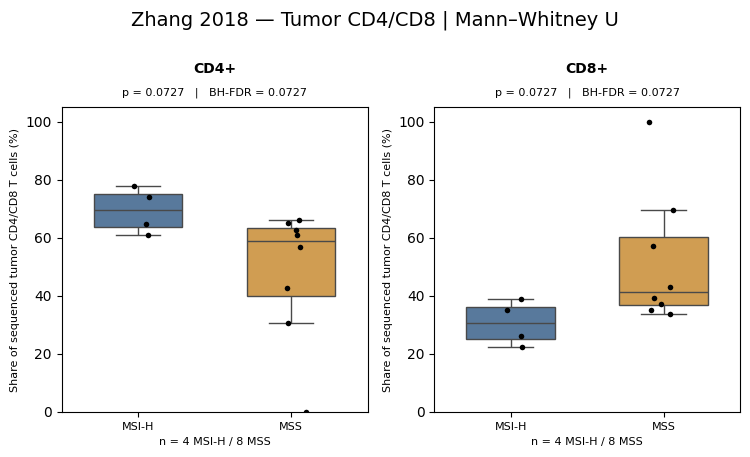

In [77]:
plot_msi_test(
    major_pct, major_tests, method="MW",
    title="Zhang 2018 — Tumor CD4/CD8 | Mann–Whitney U",
    filename="tumor_major_mannwhitney_pvalues.png",
    columns_per_row=2,
    ylabel="Share of sequenced tumor CD4/CD8 T cells (%)"
)

### 6.5 Major CD4/CD8 — Welch t-test

A separate mean-comparison figure, with Welch p-values and BH-adjusted p-values. CD4 and CD8 percentages are complementary, so they do not represent two independent discoveries.

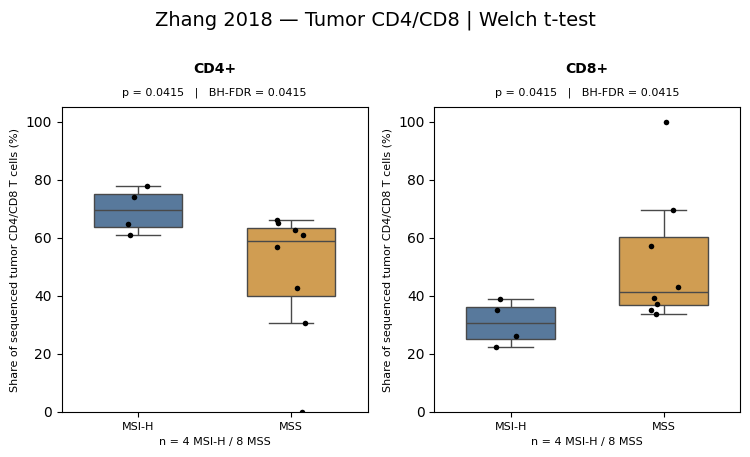

In [78]:
plot_msi_test(
    major_pct, major_tests, method="Welch",
    title="Zhang 2018 — Tumor CD4/CD8 | Welch t-test",
    filename="tumor_major_welch_pvalues.png",
    columns_per_row=2,
    ylabel="Share of sequenced tumor CD4/CD8 T cells (%)"
)

### 6.6 Twenty subclusters — Mann–Whitney U

Twenty subcluster plots (within each CD4 or CD8 lineage); patient points and each subtype's own Mann–Whitney p/FDR appear in each panel.

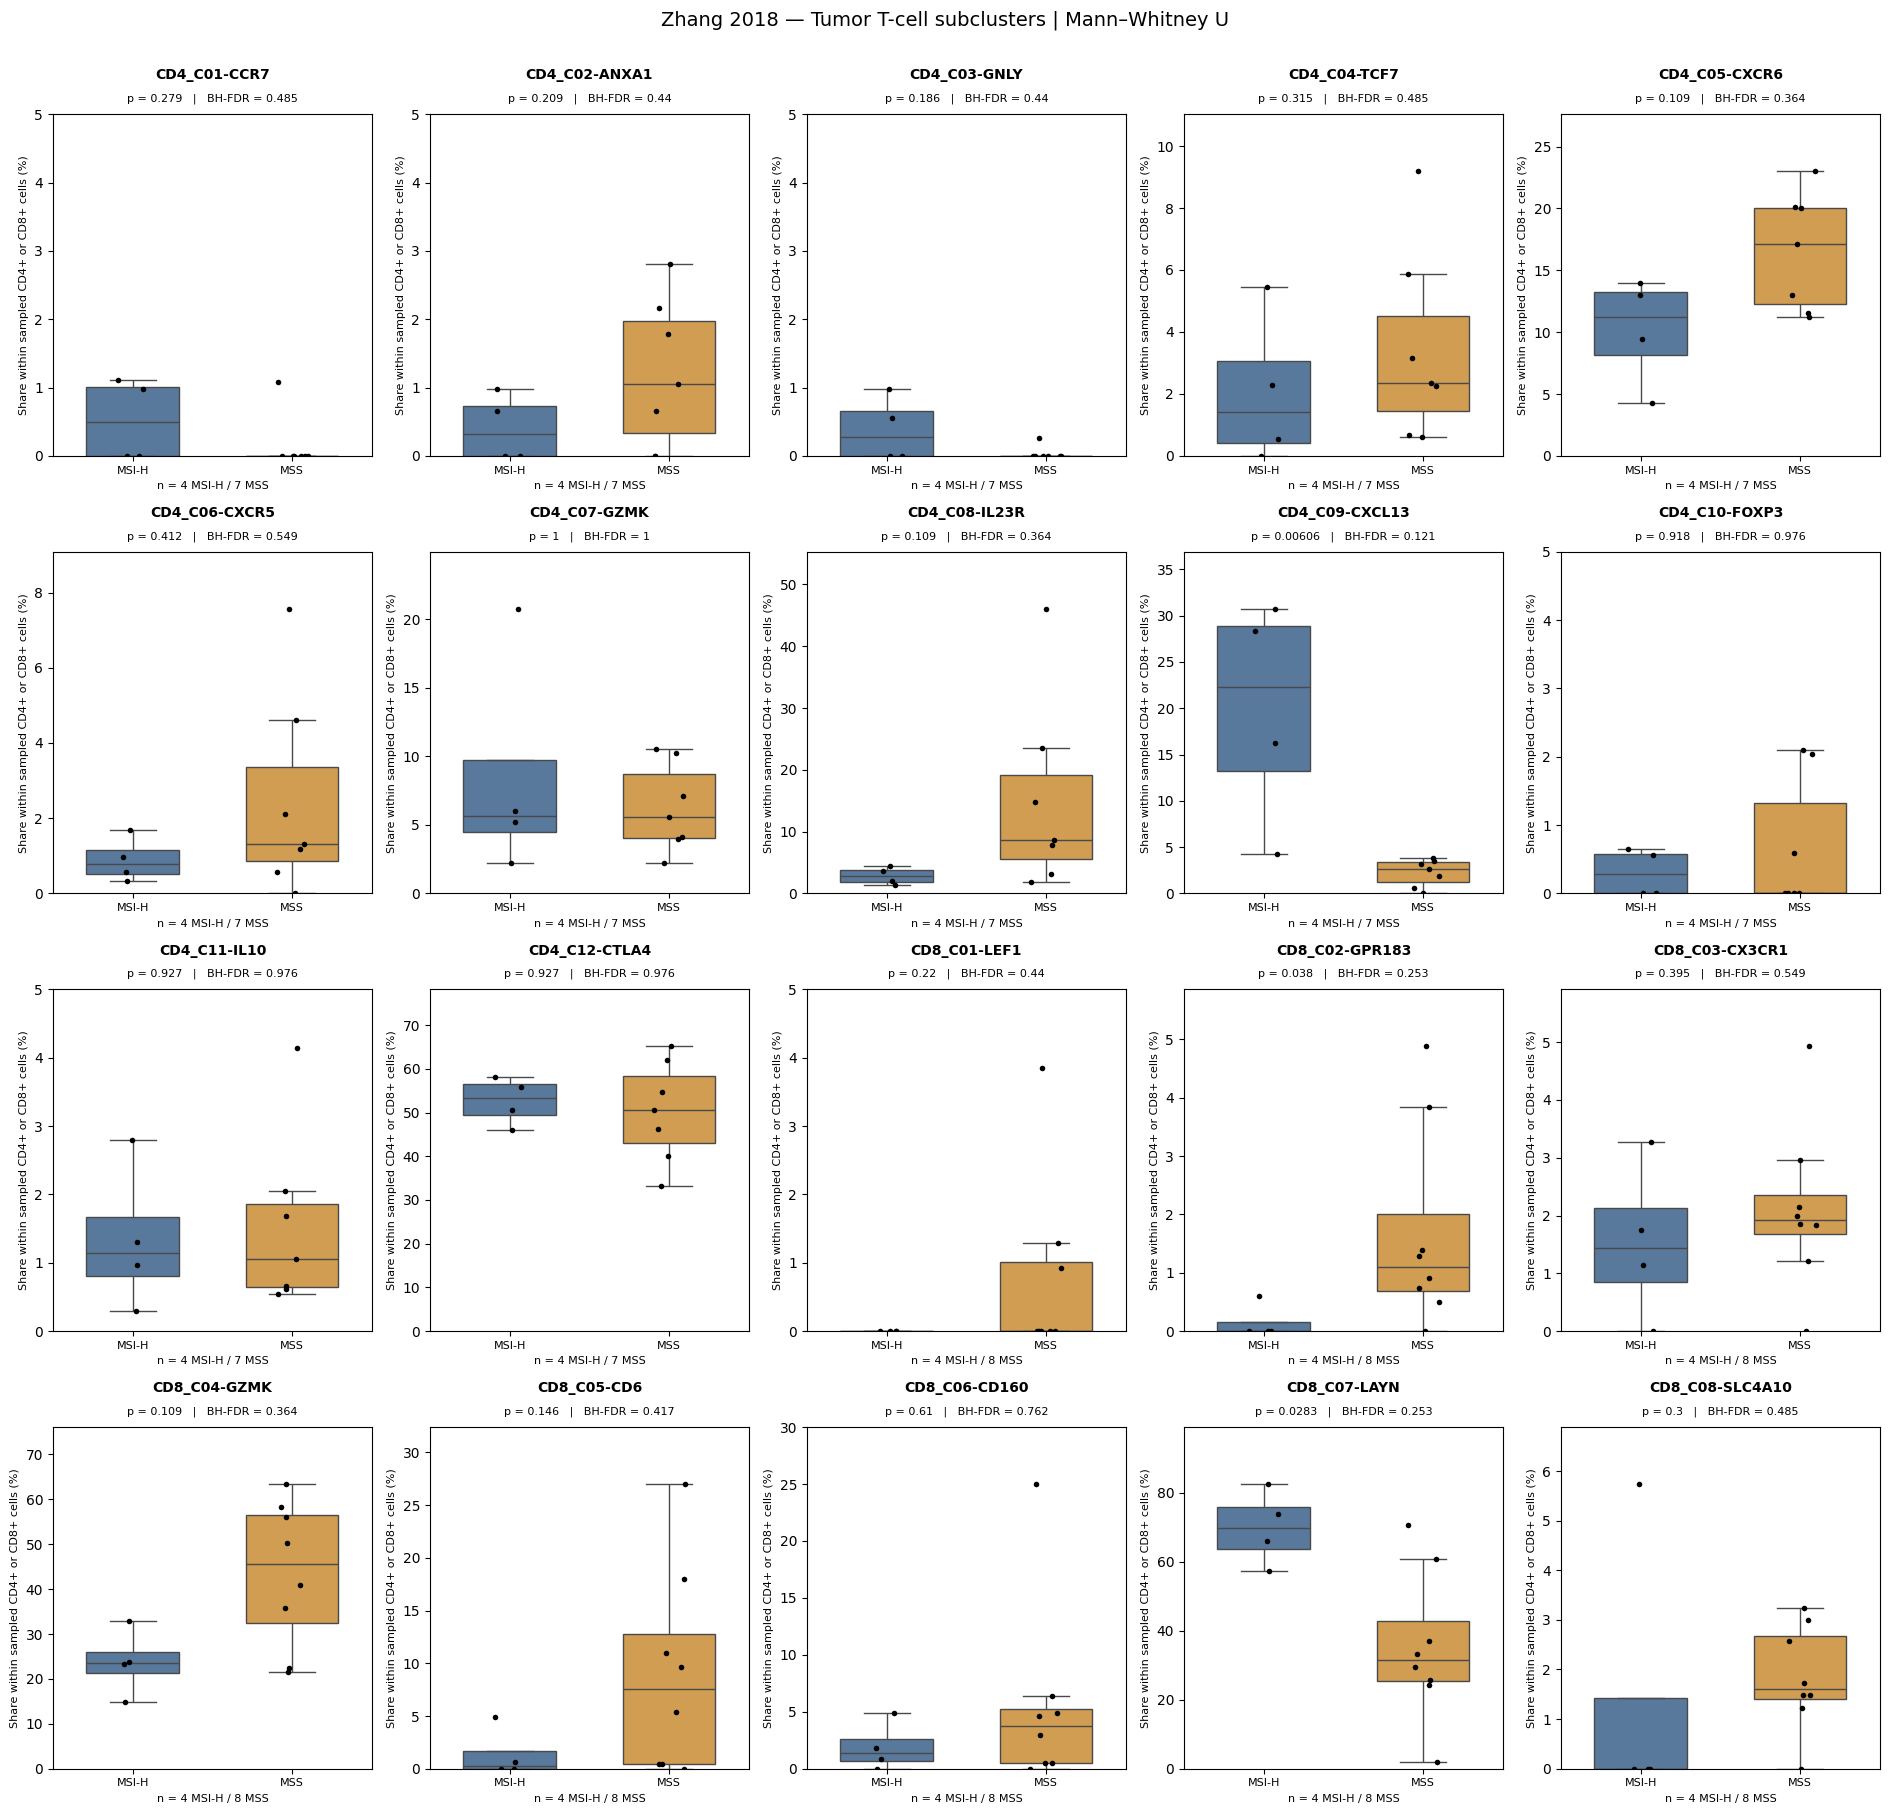

In [79]:
plot_msi_test(
    subcluster_pct_within_lineage, subcluster_tests, method="MW",
    title="Zhang 2018 — Tumor T-cell subclusters | Mann–Whitney U",
    filename="tumor_subclusters_mannwhitney_pvalues.png",
    columns_per_row=5,
    ylabel="Share within sampled CD4+ or CD8+ cells (%)"
)

### 6.7 Twenty subclusters — Welch t-test

The same patient-level percentages, now testing mean differences using Welch's t-test. Interpretation should account for small groups, skew and outliers.

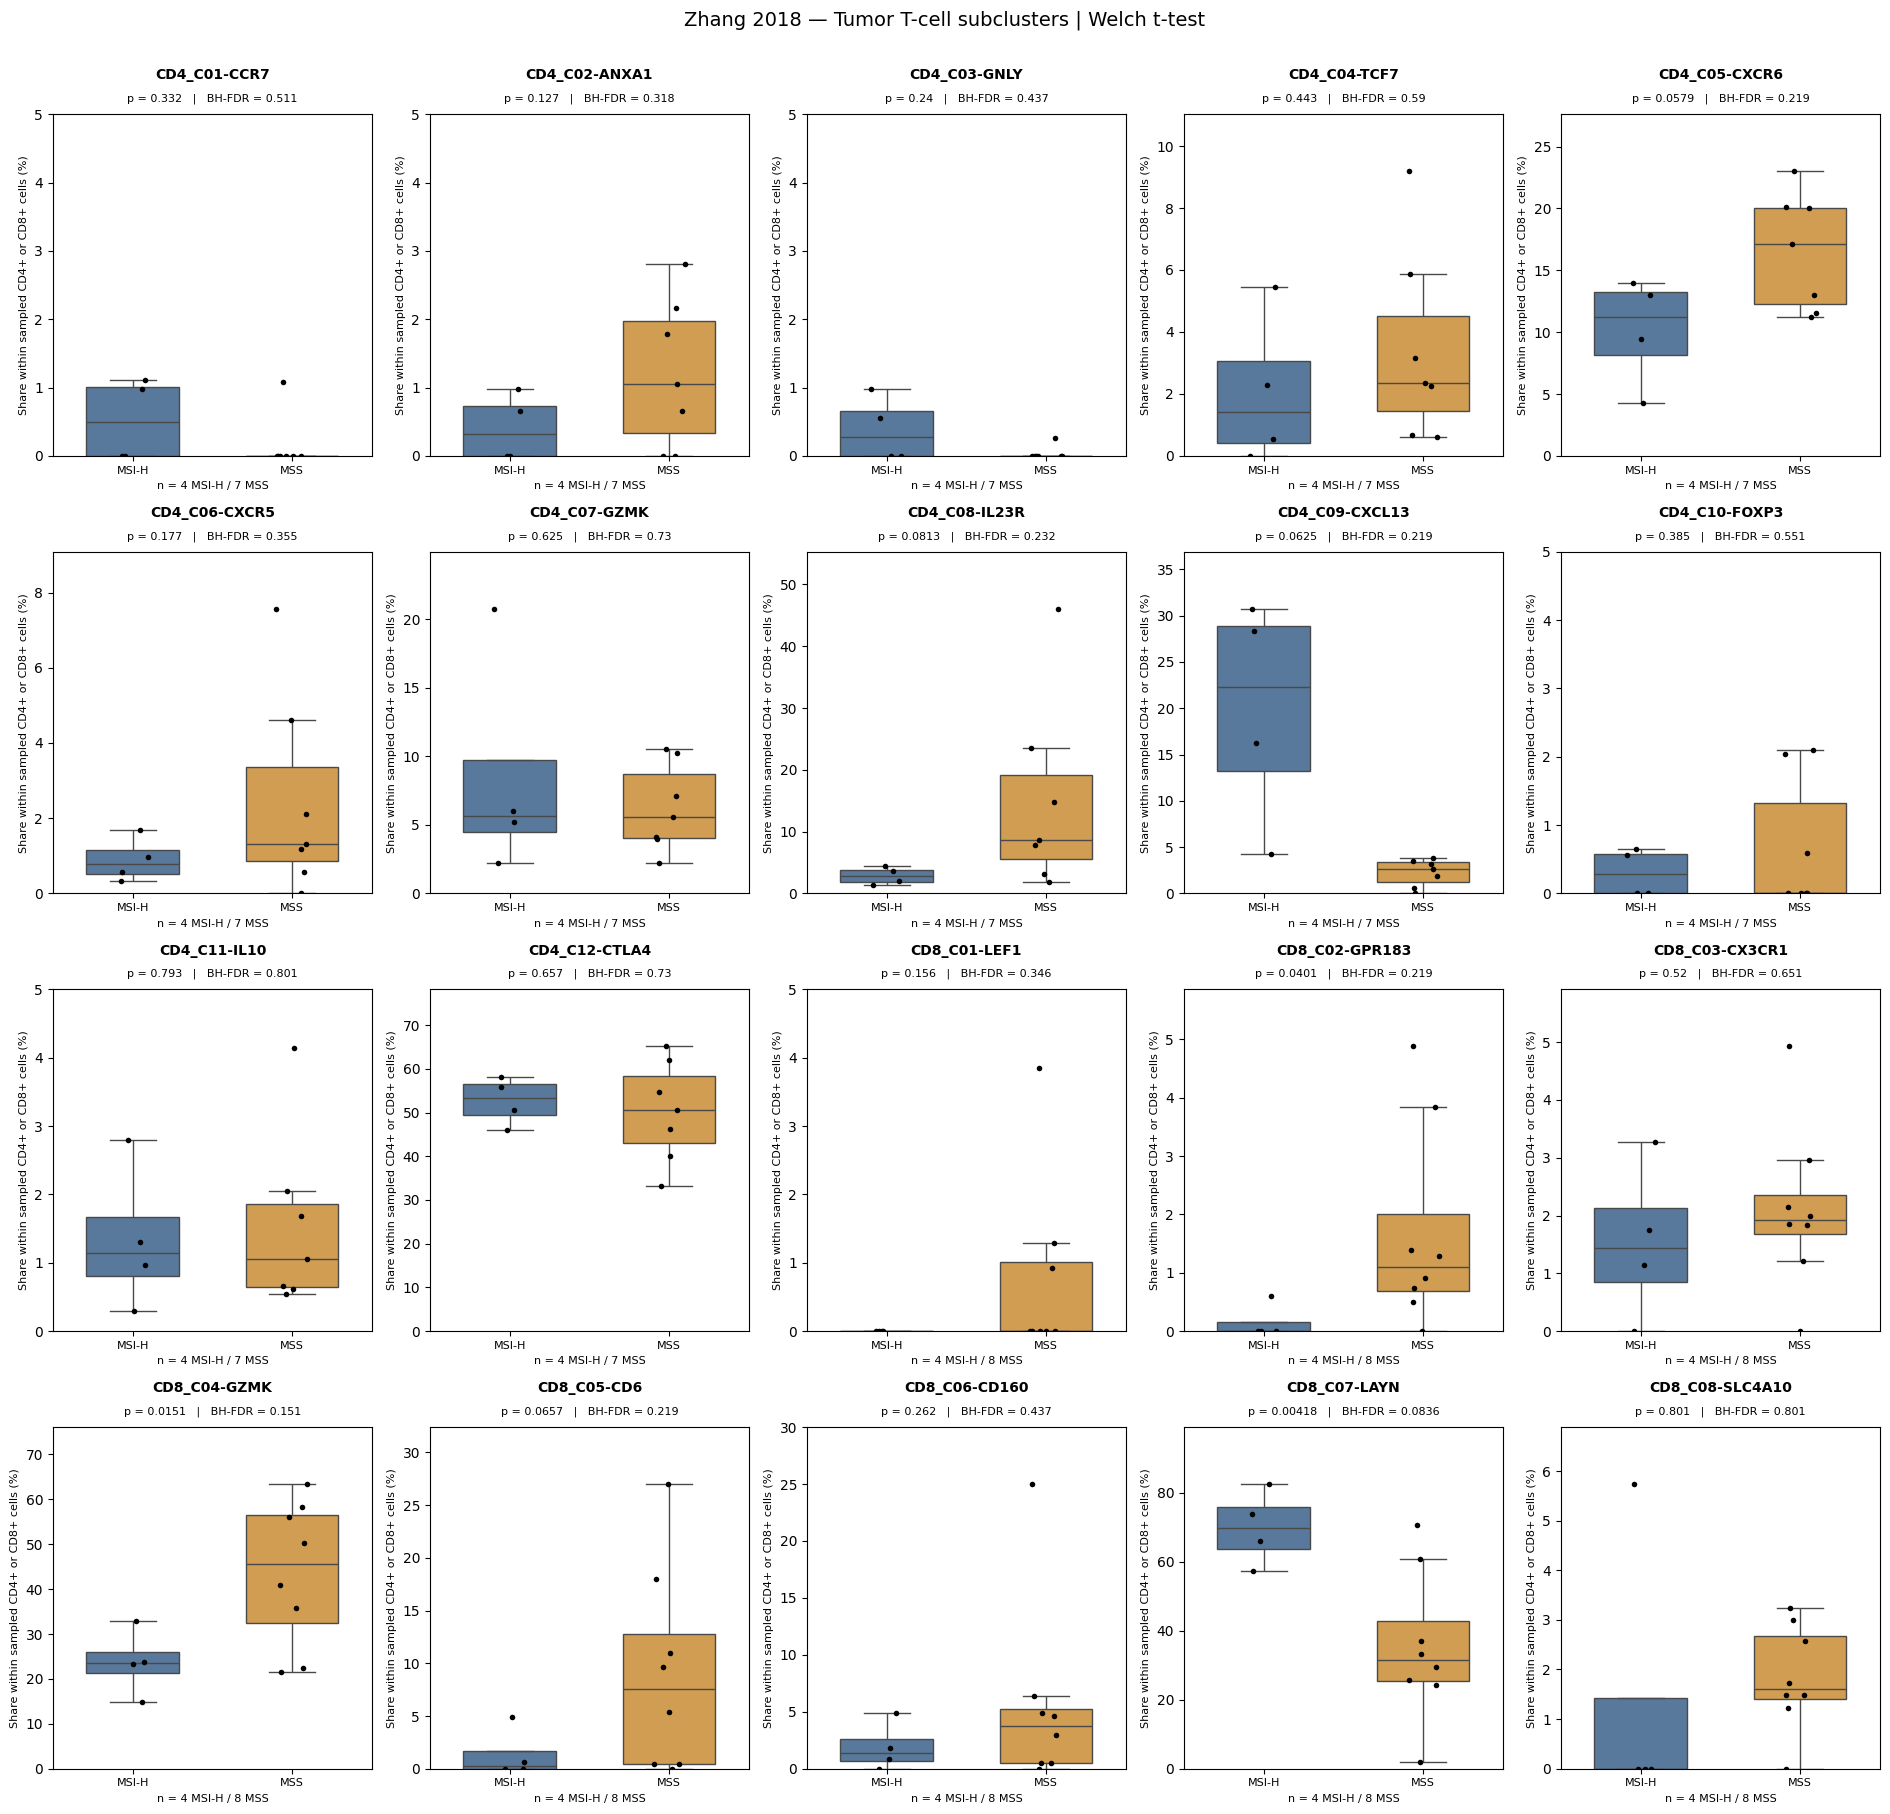

In [80]:
plot_msi_test(
    subcluster_pct_within_lineage, subcluster_tests, method="Welch",
    title="Zhang 2018 — Tumor T-cell subclusters | Welch t-test",
    filename="tumor_subclusters_welch_pvalues.png",
    columns_per_row=5,
    ylabel="Share within sampled CD4+ or CD8+ cells (%)"
)

### 6.8 Interpretation and reporting notes

Choose a **primary analysis before interpreting significance** (Mann–Whitney U is our default); Welch is a sensitivity/mean-comparison analysis. Do not select whichever gives the smaller p-value. The primary and supporting results are from the same patients, not independent validation. Report group sample sizes, median or mean as appropriate, raw p-values and BH-adjusted p-values; no BH-FDR < 0.05 means no discovery at that threshold. Note that CD4 lineage subclusters have 4 MSI-H and 7 MSS usable patients because one MSS patient has no sampled tumor CD4 cells, whereas major/CD8 analyses have 4 and 8.

## 7. Machine learning (future work)
...